# Behavior features

Explore feature geometry and construct raw and rolling behavior descriptors.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Phase 2.ipynb`, original cells 0–63 (zero-based).


In [ ]:
from pathlib import Path
import os
import sys

# Locate the repository from its root or any notebook subdirectory.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "tradinguni_paths.py").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from inside the TradingUni repository.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from tradinguni_paths import data_path, output_path
os.chdir(REPO_ROOT)


In [ ]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

df = pl.read_parquet(str(data_path("0.Data -> Facts/phase_data/phase_1_ETH_1min_Market_Structure_Feature.parquet")))

In [ ]:
df

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,signed_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,active_ms,intensity_peak_1s,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_q,…,sign_entropy,n_trans,run_max,run_mean,is_sparse_stats,is_sparse_seq,is_sparse_top1,gap_ms_from_last_trade,is_no_trade_fill,is_missing_fill,A_t,F_t,P_t,C_t,V_t,I_t,eps_I,I_t_filled,V_log,F_raw,Fabs_log,A_raw,P_raw,C_raw,I_raw,rk_V_fast,rk_V_slow,rk_F_fast,rk_F_slow,rk_Fabs_fast,rk_Fabs_slow,rk_A_fast,rk_A_slow,rk_P_fast,rk_P_slow,rk_C_fast,rk_C_slow
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,f64,f64,u32,u32,u32,f64,f64,u32,f64,…,f64,i32,i64,f64,bool,bool,bool,i64,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,-14936.675619,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,87,7,0.000002,0.539326,41,16,25,0.06,-0.06,89,3.393854,…,1.126515,89,27,4.090909,false,false,false,0,false,false,0.00145,null,0.187391,0.232843,0.001296,0.000009,0.039417,0.000009,0.001296,null,null,0.00145,0.187391,0.232843,0.000009,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,4762.760775,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,36,9,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,3.025684,…,1.331309,38,13,2.6,false,false,true,0,false,false,0.0006,null,0.039663,null,0.000605,0.000006,0.015228,0.000006,0.000605,null,null,0.0006,0.039663,null,0.000006,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,14302.818578,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,35,5,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,3.828299,…,1.253421,36,8,3.7,false,false,true,0,false,false,0.000583,null,0.095848,null,0.000956,0.000001,0.018269,0.000001,0.000955,null,null,0.000583,0.095848,null,0.000001,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,359.690972,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,33,5,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,0.856328,…,1.373974,33,5,2.266667,false,false,true,0,false,false,0.00055,null,0.008887,null,0.000802,0.000083,0.003755,0.000083,0.000802,null,null,0.00055,0.008887,null,0.000083,null,null,null,null,null,null,null,null,null,null,null,null
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,2260.623816,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,42,9,0.000001,0.352941,33,13,20,0.05,-0.04,51,1.971218,…,1.259017,51,11,3.714286,false,false,false,0,false,false,0.0007,null,0.091812,0.390877,0.001067,0.00004,0.01321,0.00004,0.001066,null,null,0.0007,0.091812,0.390877,0.00004,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.14,2971.82,2971.13,2971.82,22.8505,67897.53557,139.0,117.0,22.0,64144.830718,3752.704852,60392.125866,2971.380739,2.316667,0.88946,0.69,0.000232,2971.13,0.000229,0.000232,0.000003,430.536232,1.0,1357.0,0.456522,76,45,1.6535e-9,0.449275,

# Geometry & Distribution

## Graph

In [ ]:
df_week = df.filter(
    (pl.col("t") >= pl.datetime(2024, 10, 1)) &
    (pl.col("t") <= pl.datetime(2024, 10, 31))
)

cols = [
    "A_raw","Fabs_log","P_raw","C_raw","V_log","I_raw",
    "rk_V_fast","rk_V_slow","rk_F_fast","rk_F_slow",
    "rk_A_fast","rk_A_slow","rk_P_fast","rk_P_slow",
    "rk_C_fast","rk_C_slow"
]

# แปลงเป็น pandas ก่อน
pdf = df_week.select(["t", "close", *cols]).to_pandas()

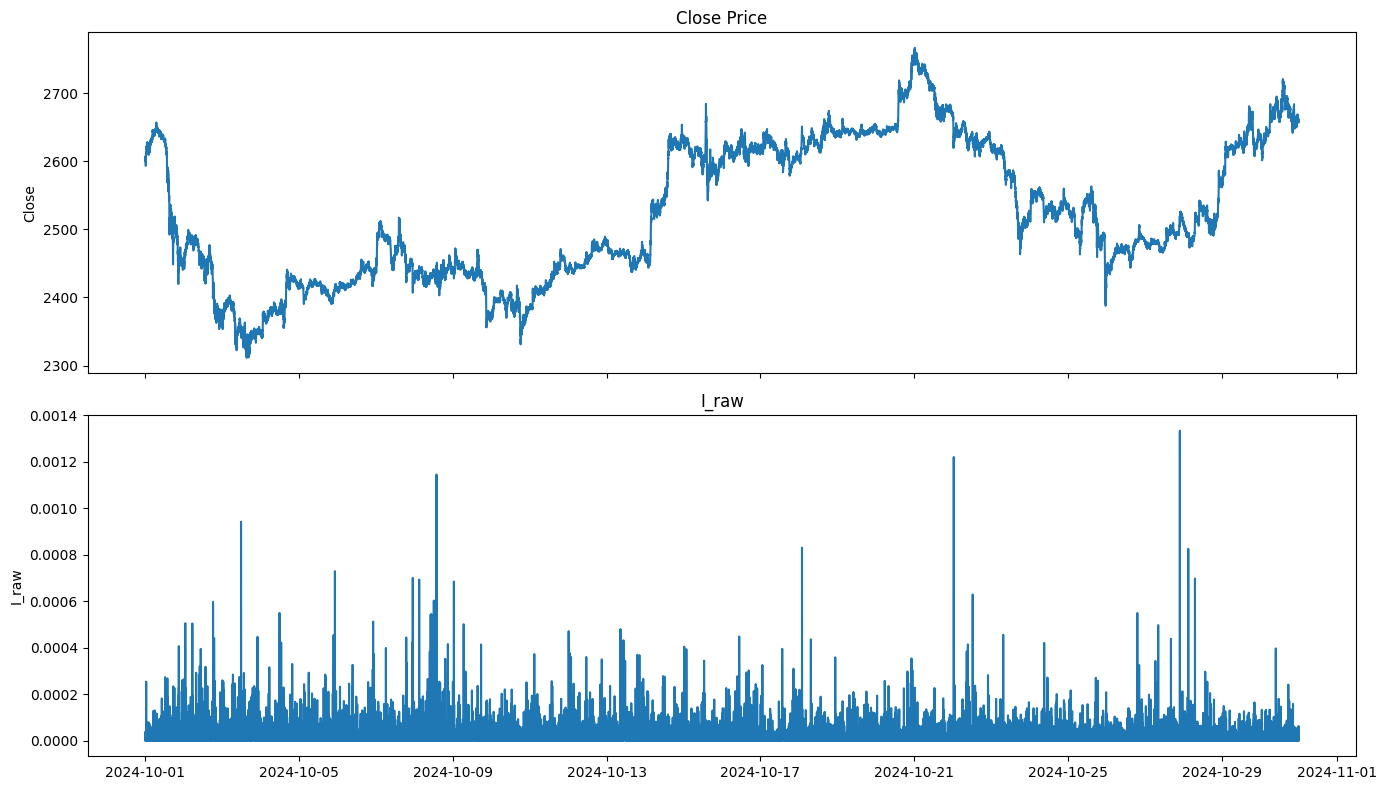

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8)
)

axes[0].plot(pdf["t"], pdf["close"])
axes[0].set_ylabel("Close")
axes[0].set_title("Close Price")

axes[1].plot(pdf["t"], pdf["I_raw"])
axes[1].set_ylabel("I_raw")
axes[1].set_title("I_raw")

plt.tight_layout()
plt.show()

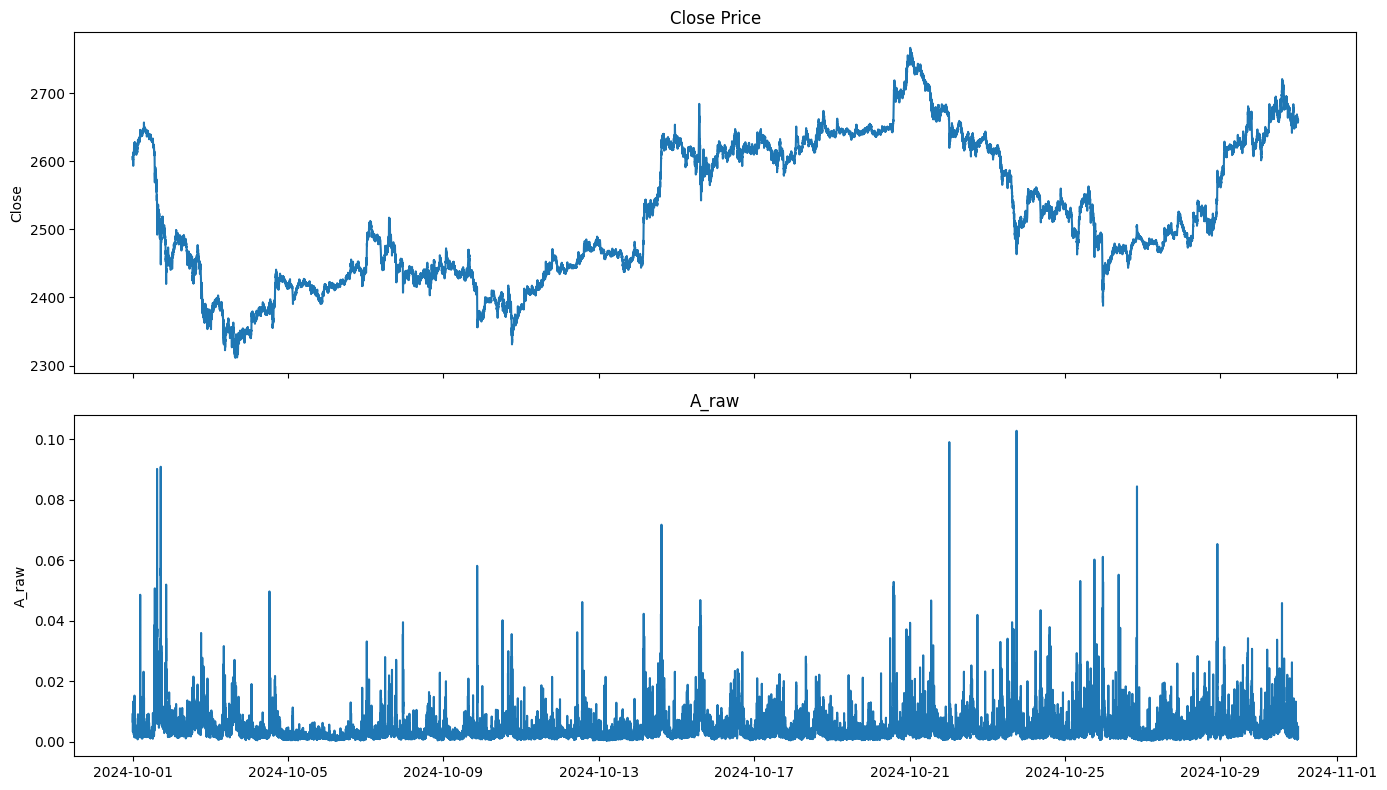

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8)
)

# 1) Close price
axes[0].plot(pdf["t"], pdf["close"])
axes[0].set_ylabel("Close")
axes[0].set_title("Close Price")

# 2) A_t
axes[1].plot(pdf["t"], pdf["A_raw"])
axes[1].set_ylabel("A_raw")
axes[1].set_title("A_raw")

# # 3) rk_A_fast
# axes[2].plot(pdf["t"], pdf["rk_A_fast"])
# axes[2].set_ylabel("rk_A_fast")
# axes[2].set_title("rk_A_fast")

# # 4) rk_A_slow
# axes[3].plot(pdf["t"], pdf["rk_A_slow"])
# axes[3].set_ylabel("rk_A_slow")
# axes[3].set_title("rk_A_slow")

plt.tight_layout()
plt.show()

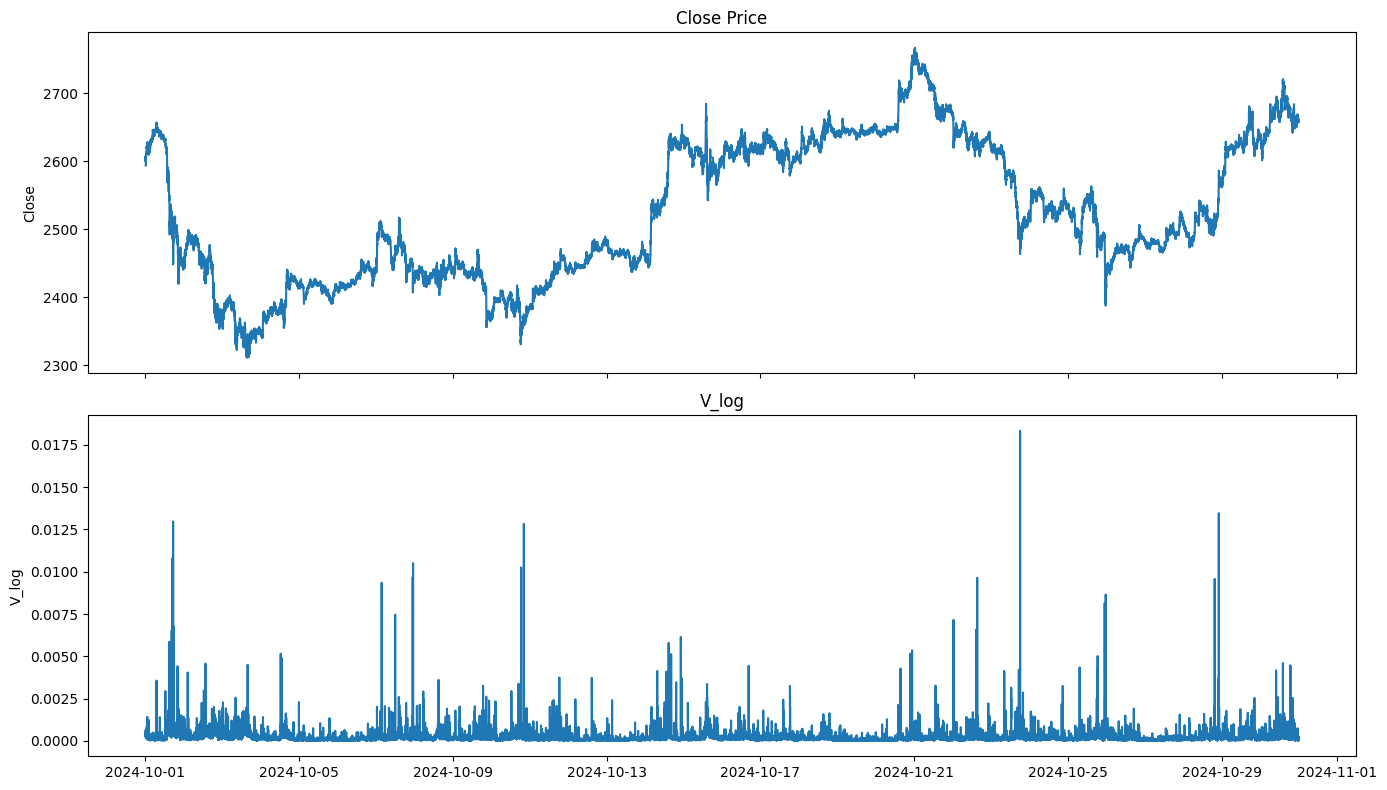

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8)
)

axes[0].plot(pdf["t"], pdf["close"])
axes[0].set_ylabel("Close")
axes[0].set_title("Close Price")

axes[1].plot(pdf["t"], pdf["V_log"])
axes[1].set_ylabel("V_log")
axes[1].set_title("V_log")

# axes[2].plot(pdf["t"], pdf["rk_V_fast"])
# axes[2].set_ylabel("rk_V_fast")
# axes[2].set_title("rk_V_fast")

# axes[3].plot(pdf["t"], pdf["rk_V_slow"])
# axes[3].set_ylabel("rk_V_slow")
# axes[3].set_title("rk_V_slow")

plt.tight_layout()
plt.show()

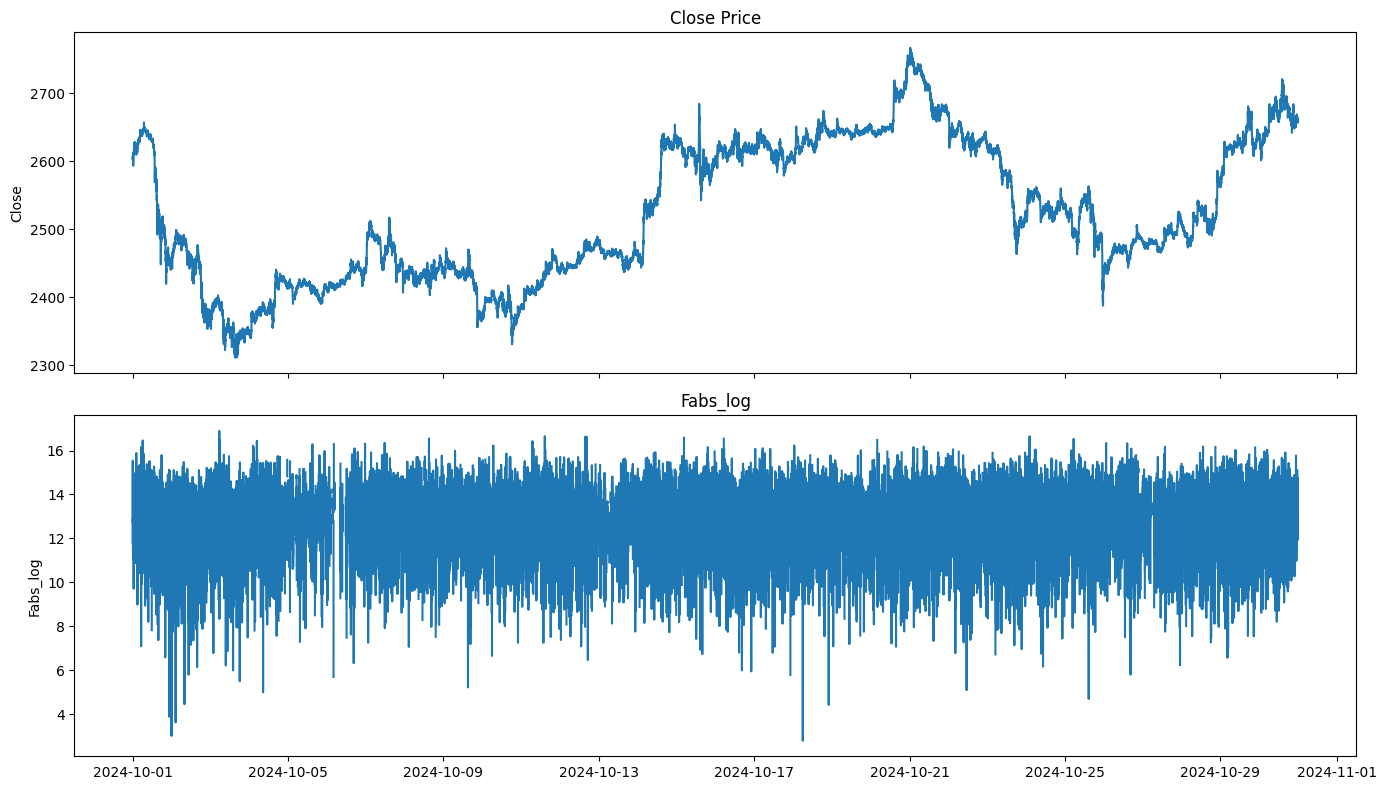

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8)
)

axes[0].plot(pdf["t"], pdf["close"])
axes[0].set_ylabel("Close")
axes[0].set_title("Close Price")

axes[1].plot(pdf["t"], pdf["Fabs_log"])
axes[1].set_ylabel("Fabs_log")
axes[1].set_title("Fabs_log")

# axes[2].plot(pdf["t"], pdf["rk_F_fast"])
# axes[2].set_ylabel("rk_F_fast")
# axes[2].set_title("rk_F_fast")

# axes[3].plot(pdf["t"], pdf["rk_F_slow"])
# axes[3].set_ylabel("rk_F_slow")
# axes[3].set_title("rk_F_slow")

plt.tight_layout()
plt.show()

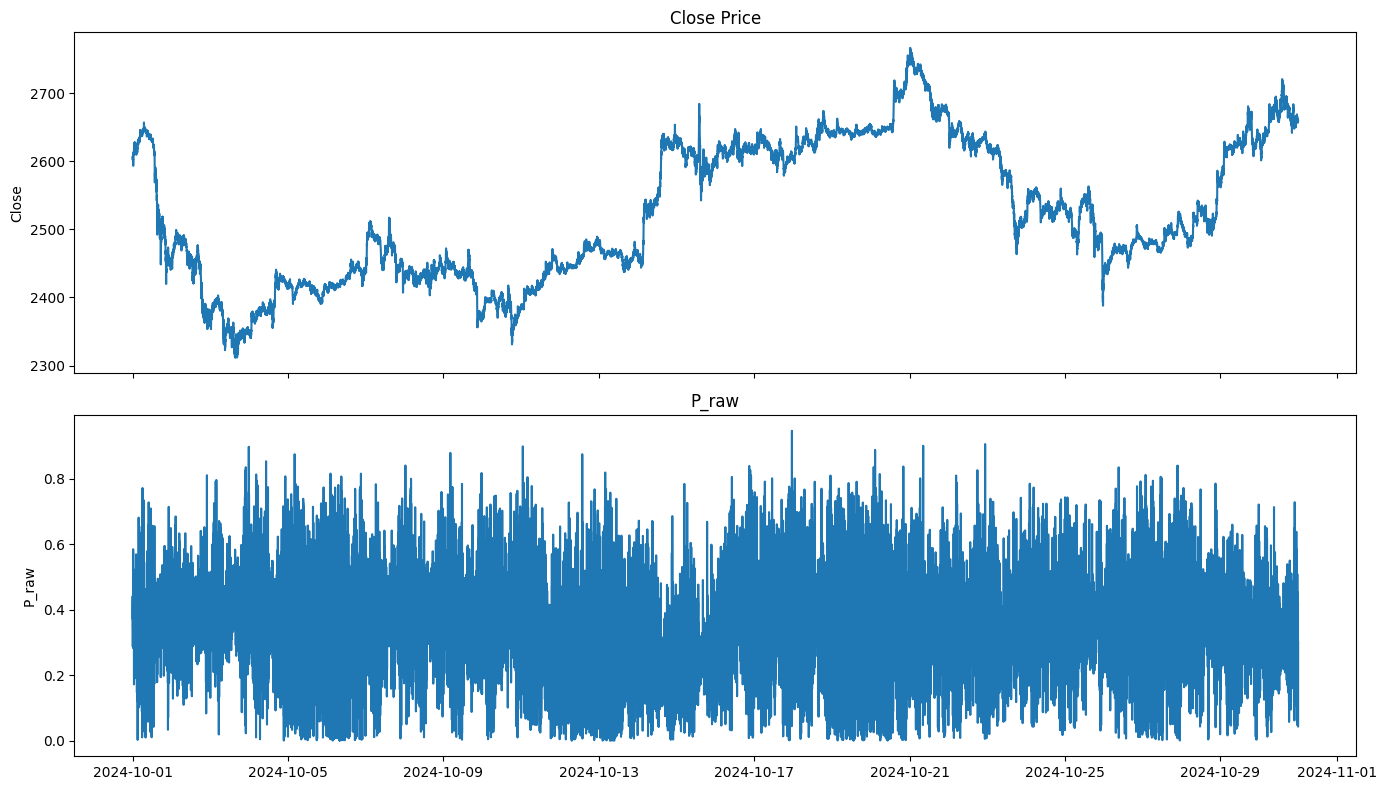

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8)
)

axes[0].plot(pdf["t"], pdf["close"])
axes[0].set_ylabel("Close")
axes[0].set_title("Close Price")

axes[1].plot(pdf["t"], pdf["P_raw"])
axes[1].set_ylabel("P_raw")
axes[1].set_title("P_raw")

# axes[2].plot(pdf["t"], pdf["rk_P_fast"])
# axes[2].set_ylabel("rk_P_fast")
# axes[2].set_title("rk_P_fast")

# axes[3].plot(pdf["t"], pdf["rk_P_slow"])
# axes[3].set_ylabel("rk_P_slow")
# axes[3].set_title("rk_P_slow")

plt.tight_layout()
plt.show()

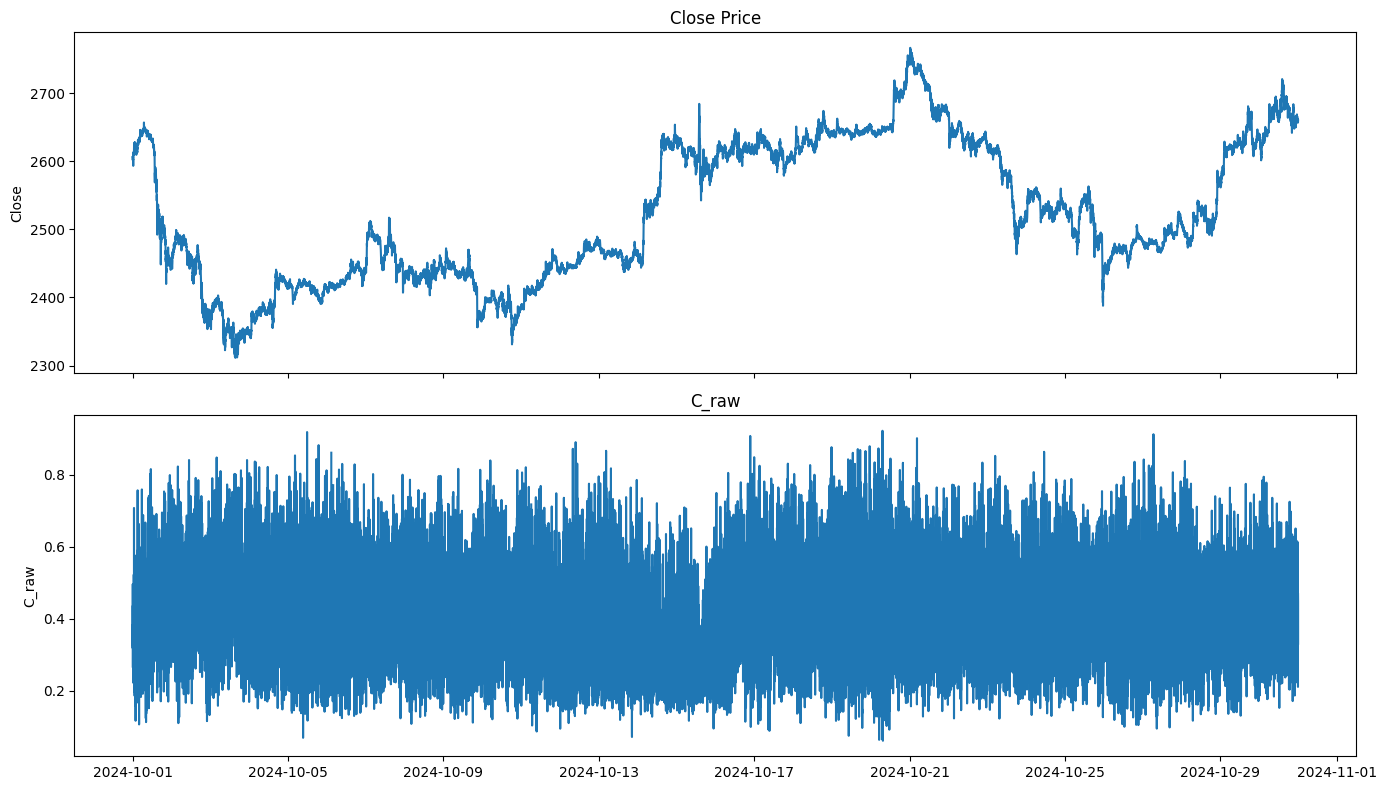

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8)
)

axes[0].plot(pdf["t"], pdf["close"])
axes[0].set_ylabel("Close")
axes[0].set_title("Close Price")

axes[1].plot(pdf["t"], pdf["C_raw"])
axes[1].set_ylabel("C_raw")
axes[1].set_title("C_raw")

# axes[2].plot(pdf["t"], pdf["rk_C_fast"])
# axes[2].set_ylabel("rk_C_fast")
# axes[2].set_title("rk_C_fast")

# axes[3].plot(pdf["t"], pdf["rk_C_slow"])
# axes[3].set_ylabel("rk_C_slow")
# axes[3].set_title("rk_C_slow")

plt.tight_layout()
plt.show()

## Dist

### Global

NameError: name 'df' is not defined

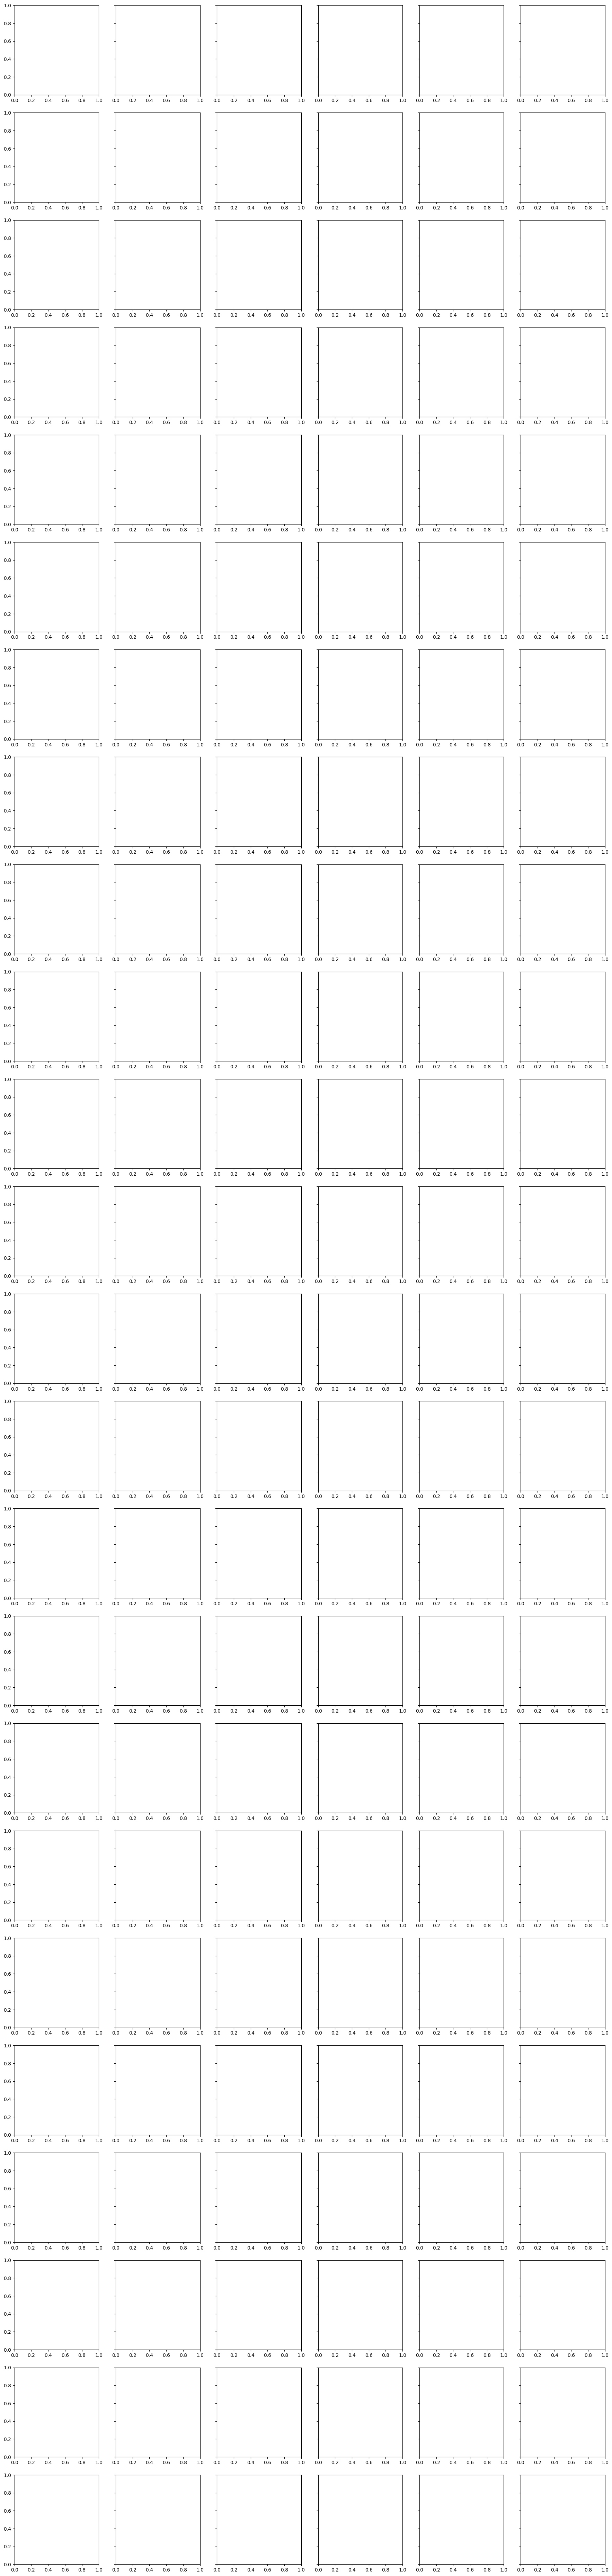

In [1]:
cols = [
    "V_log",
    "Fabs_log",
    "A_raw",
    "P_raw",
    "C_raw",
    "I_raw"
]

special_cols = ["A_raw", "V_log", "I_raw"]

fig, axes = plt.subplots(1, len(cols), figsize=(22, 4), sharey=True)
axes = axes.flatten()

for ax, c in zip(axes, cols):
    data = df.select(c).to_series().drop_nulls().to_numpy()

    if c in special_cols:
        p95 = np.percentile(data, 95)
        data = data[data < p95]
        ax.set_title(f"{c} (≤95th pct)")
    else:
        ax.set_title(f"Distribution of {c}")

    ax.hist(data, bins=200)
    ax.set_xlabel(c)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [ ]:
df.select(cols).describe()

statistic,V_log,Fabs_log,A_raw,P_raw,C_raw,I_raw
str,f64,f64,f64,f64,f64,f64
"""count""",3.153974e6,2.668868e6,3.153978e6,3.151751e6,3.093724e6,3.15413e6
"""null_count""",2506.0,487612.0,2502.0,4729.0,62756.0,2350.0
"""mean""",0.000672,12.825293,0.005351,0.149353,0.295287,0.000016
"""std""",0.00181,1.304159,0.006602,0.113825,0.124132,0.000031
"""min""",0.0,0.375302,0.00005,0.0,0.026823,0.0
"""25%""",0.000135,12.134508,0.00215,0.064194,0.202033,0.000003
"""50%""",0.000328,12.982815,0.003583,0.11475,0.269659,0.000007
"""75%""",0.000768,13.694906,0.00615,0.2178,0.3644,0.000016
"""max""",0.678238,17.753922,0.418883,1.0,0.98844,0.002503


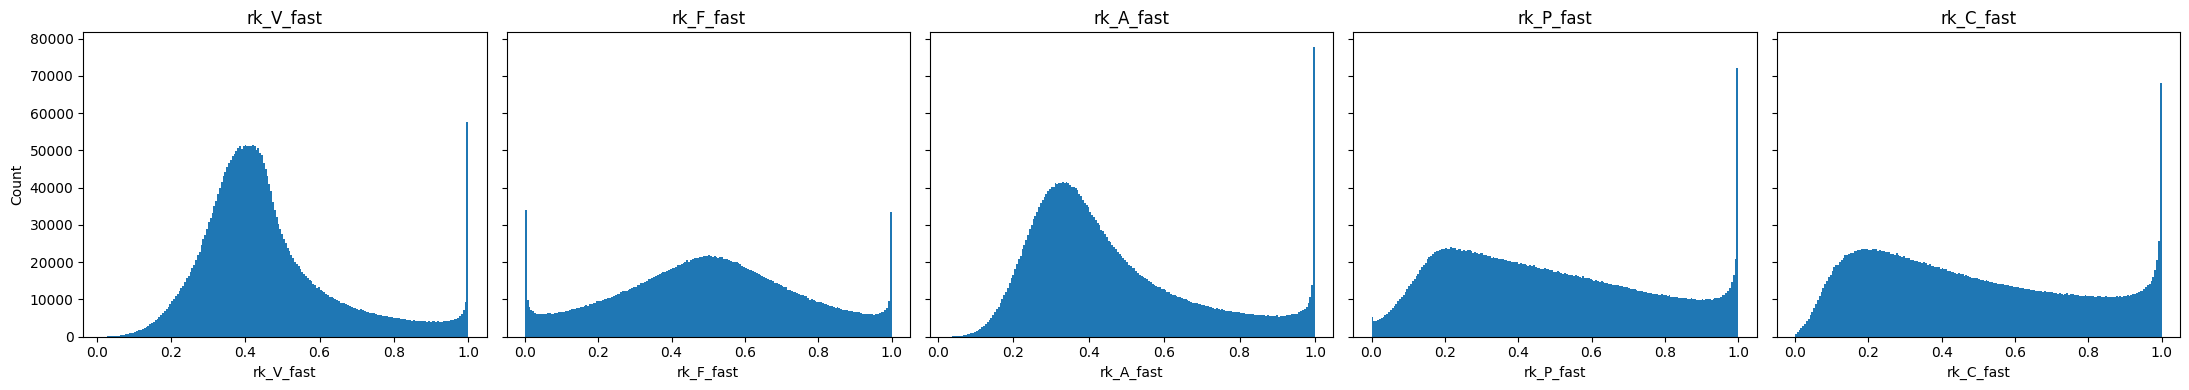

In [ ]:
cols = [
    "rk_V_fast",
    "rk_F_fast",
    "rk_A_fast",
    "rk_P_fast",
    "rk_C_fast",
]

fig, axes = plt.subplots(1, len(cols), figsize=(22, 4), sharey=True)

for ax, c in zip(axes, cols):
    data = df.select(c).to_series().drop_nulls().to_numpy()
    ax.hist(data, bins=200)
    ax.set_title(c)
    ax.set_xlabel(c)

axes[0].set_ylabel("Count")

plt.tight_layout()
plt.show()

# df.select(cols).describe()

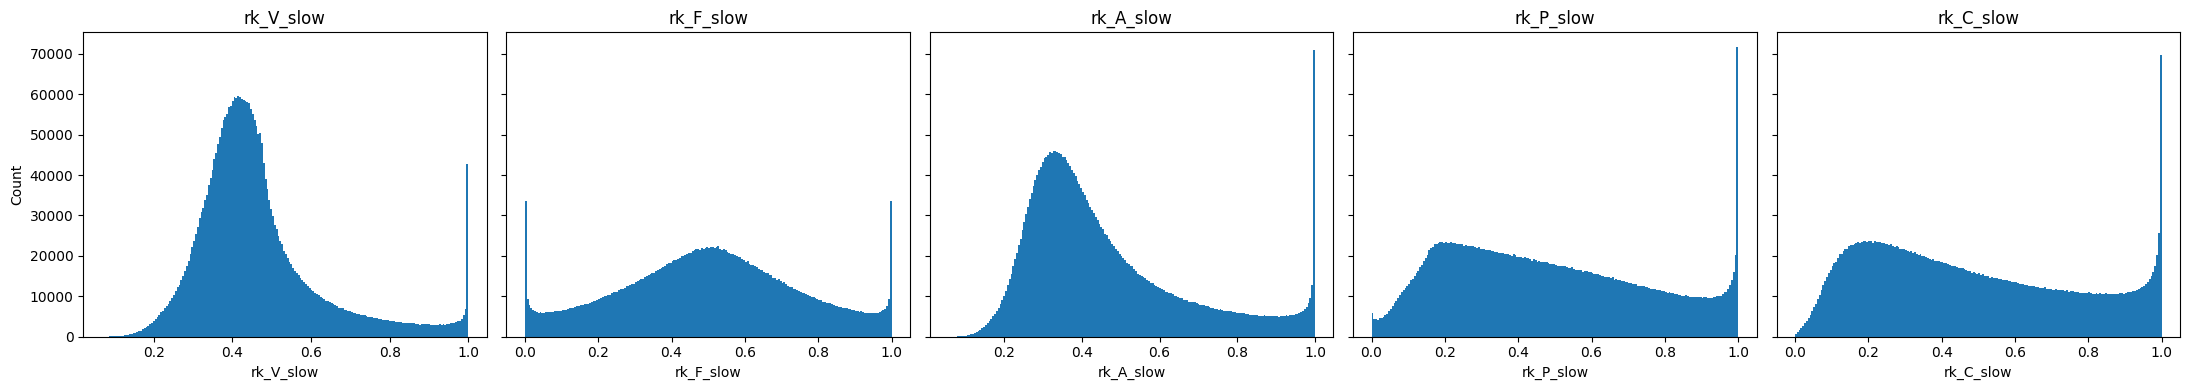

In [ ]:
cols = [
    "rk_V_slow",
    "rk_F_slow",
    "rk_A_slow",
    "rk_P_slow",
    "rk_C_slow",
]

fig, axes = plt.subplots(1, len(cols), figsize=(22, 4), sharey=True)

for ax, c in zip(axes, cols):
    data = df.select(c).to_series().drop_nulls().to_numpy()
    ax.hist(data, bins=200)
    ax.set_title(c)
    ax.set_xlabel(c)

axes[0].set_ylabel("Count")

plt.tight_layout()
plt.show()

# df.select(cols).describe()

### Tail Behavior

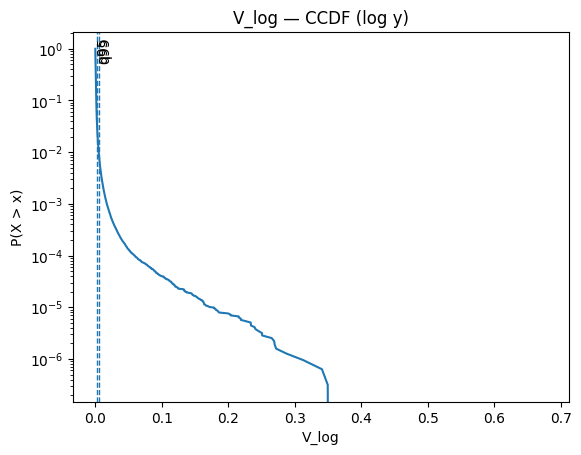

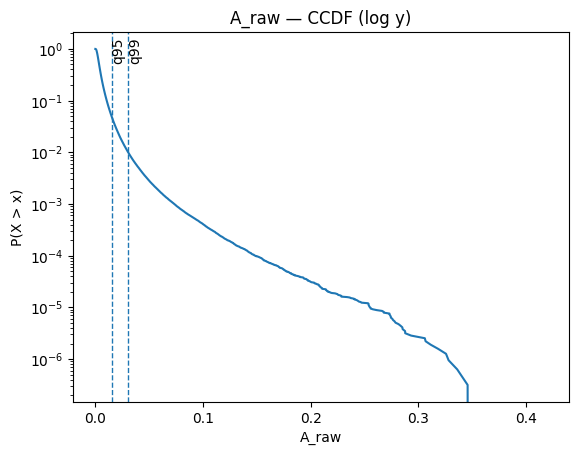

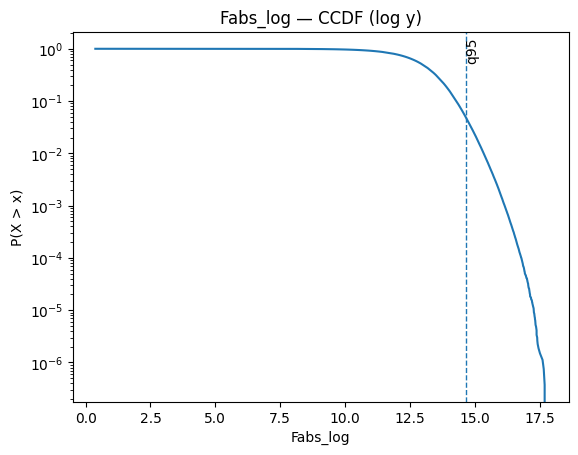

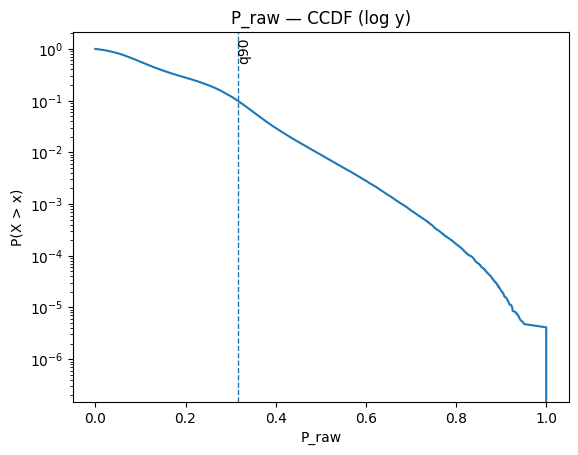

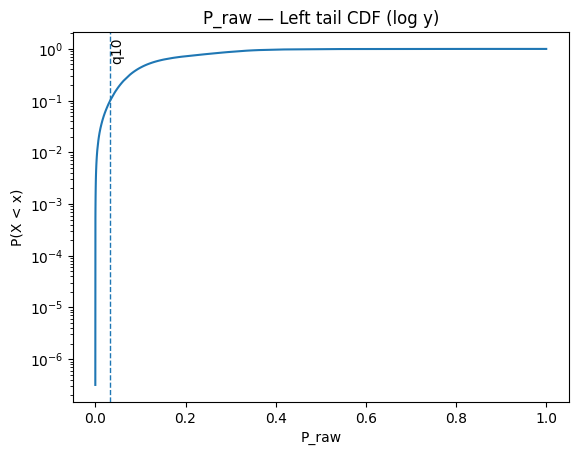

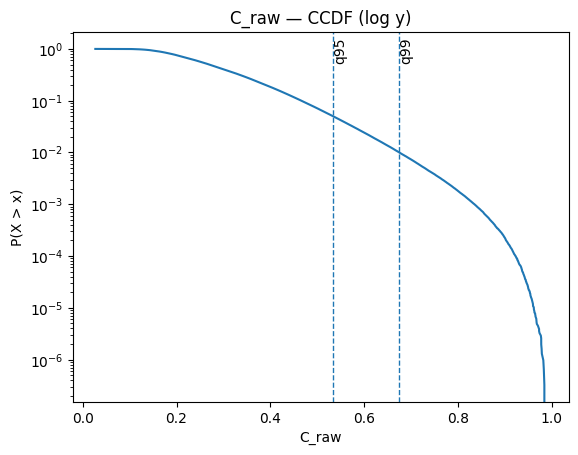

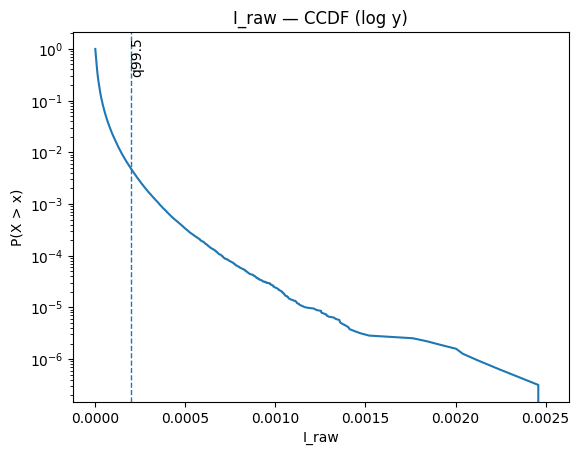

In [ ]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

def ccdf_plot(df: pl.DataFrame, col: str, qs=(0.95, 0.99), drop_nulls=True, title=None):
    s = df.select(pl.col(col)).to_series()
    if drop_nulls:
        s = s.drop_nulls()
    x = np.sort(s.to_numpy())
    if x.size == 0:
        print(f"[skip] {col}: no data")
        return

    n = x.size
    ccdf = 1.0 - (np.arange(1, n + 1) / n)

    plt.figure()
    plt.plot(x, ccdf)
    plt.yscale("log")

    for q in qs:
        v = float(np.quantile(x, q))
        plt.axvline(v, linestyle="--", linewidth=1)
        plt.text(v, plt.ylim()[1] * 0.8, f"q{q*100:g}", rotation=90, va="top")

    plt.title(title or f"{col} — CCDF (log y)")
    plt.xlabel(col)
    plt.ylabel("P(X > x)")
    plt.show()


def left_tail_plot(df: pl.DataFrame, col: str, qs=(0.10,), drop_nulls=True, title=None):
    # plot P(X < x) on log scale (left tail)
    s = df.select(pl.col(col)).to_series()
    if drop_nulls:
        s = s.drop_nulls()
    x = np.sort(s.to_numpy())
    if x.size == 0:
        print(f"[skip] {col}: no data")
        return

    n = x.size
    cdf = (np.arange(1, n + 1) / n)

    plt.figure()
    plt.plot(x, cdf)
    plt.yscale("log")

    for q in qs:
        v = float(np.quantile(x, q))
        plt.axvline(v, linestyle="--", linewidth=1)
        plt.text(v, plt.ylim()[1] * 0.8, f"q{q*100:g}", rotation=90, va="top")

    plt.title(title or f"{col} — Left tail CDF (log y)")
    plt.xlabel(col)
    plt.ylabel("P(X < x)")
    plt.show()


# ---- run for ALL features ตาม rule ของคุณ ----
FEATURE_SPECS = {
    "V_log":     {"right_qs": (0.95, 0.99)},
    "A_raw":     {"right_qs": (0.95, 0.99)},
    "Fabs_log":  {"right_qs": (0.95,)},
    "P_raw":     {"right_qs": (0.90,), "left_qs": (0.10,)},   # two-sided
    "C_raw":     {"right_qs": (0.95, 0.99)},
    "I_raw":     {"right_qs": (0.995,)},                      # I_event q99.5
}

for col, spec in FEATURE_SPECS.items():
    if "right_qs" in spec:
        ccdf_plot(df, col, qs=spec["right_qs"])
    if col == "P_raw" and "left_qs" in spec:
        left_tail_plot(df, col, qs=spec["left_qs"])

### Local

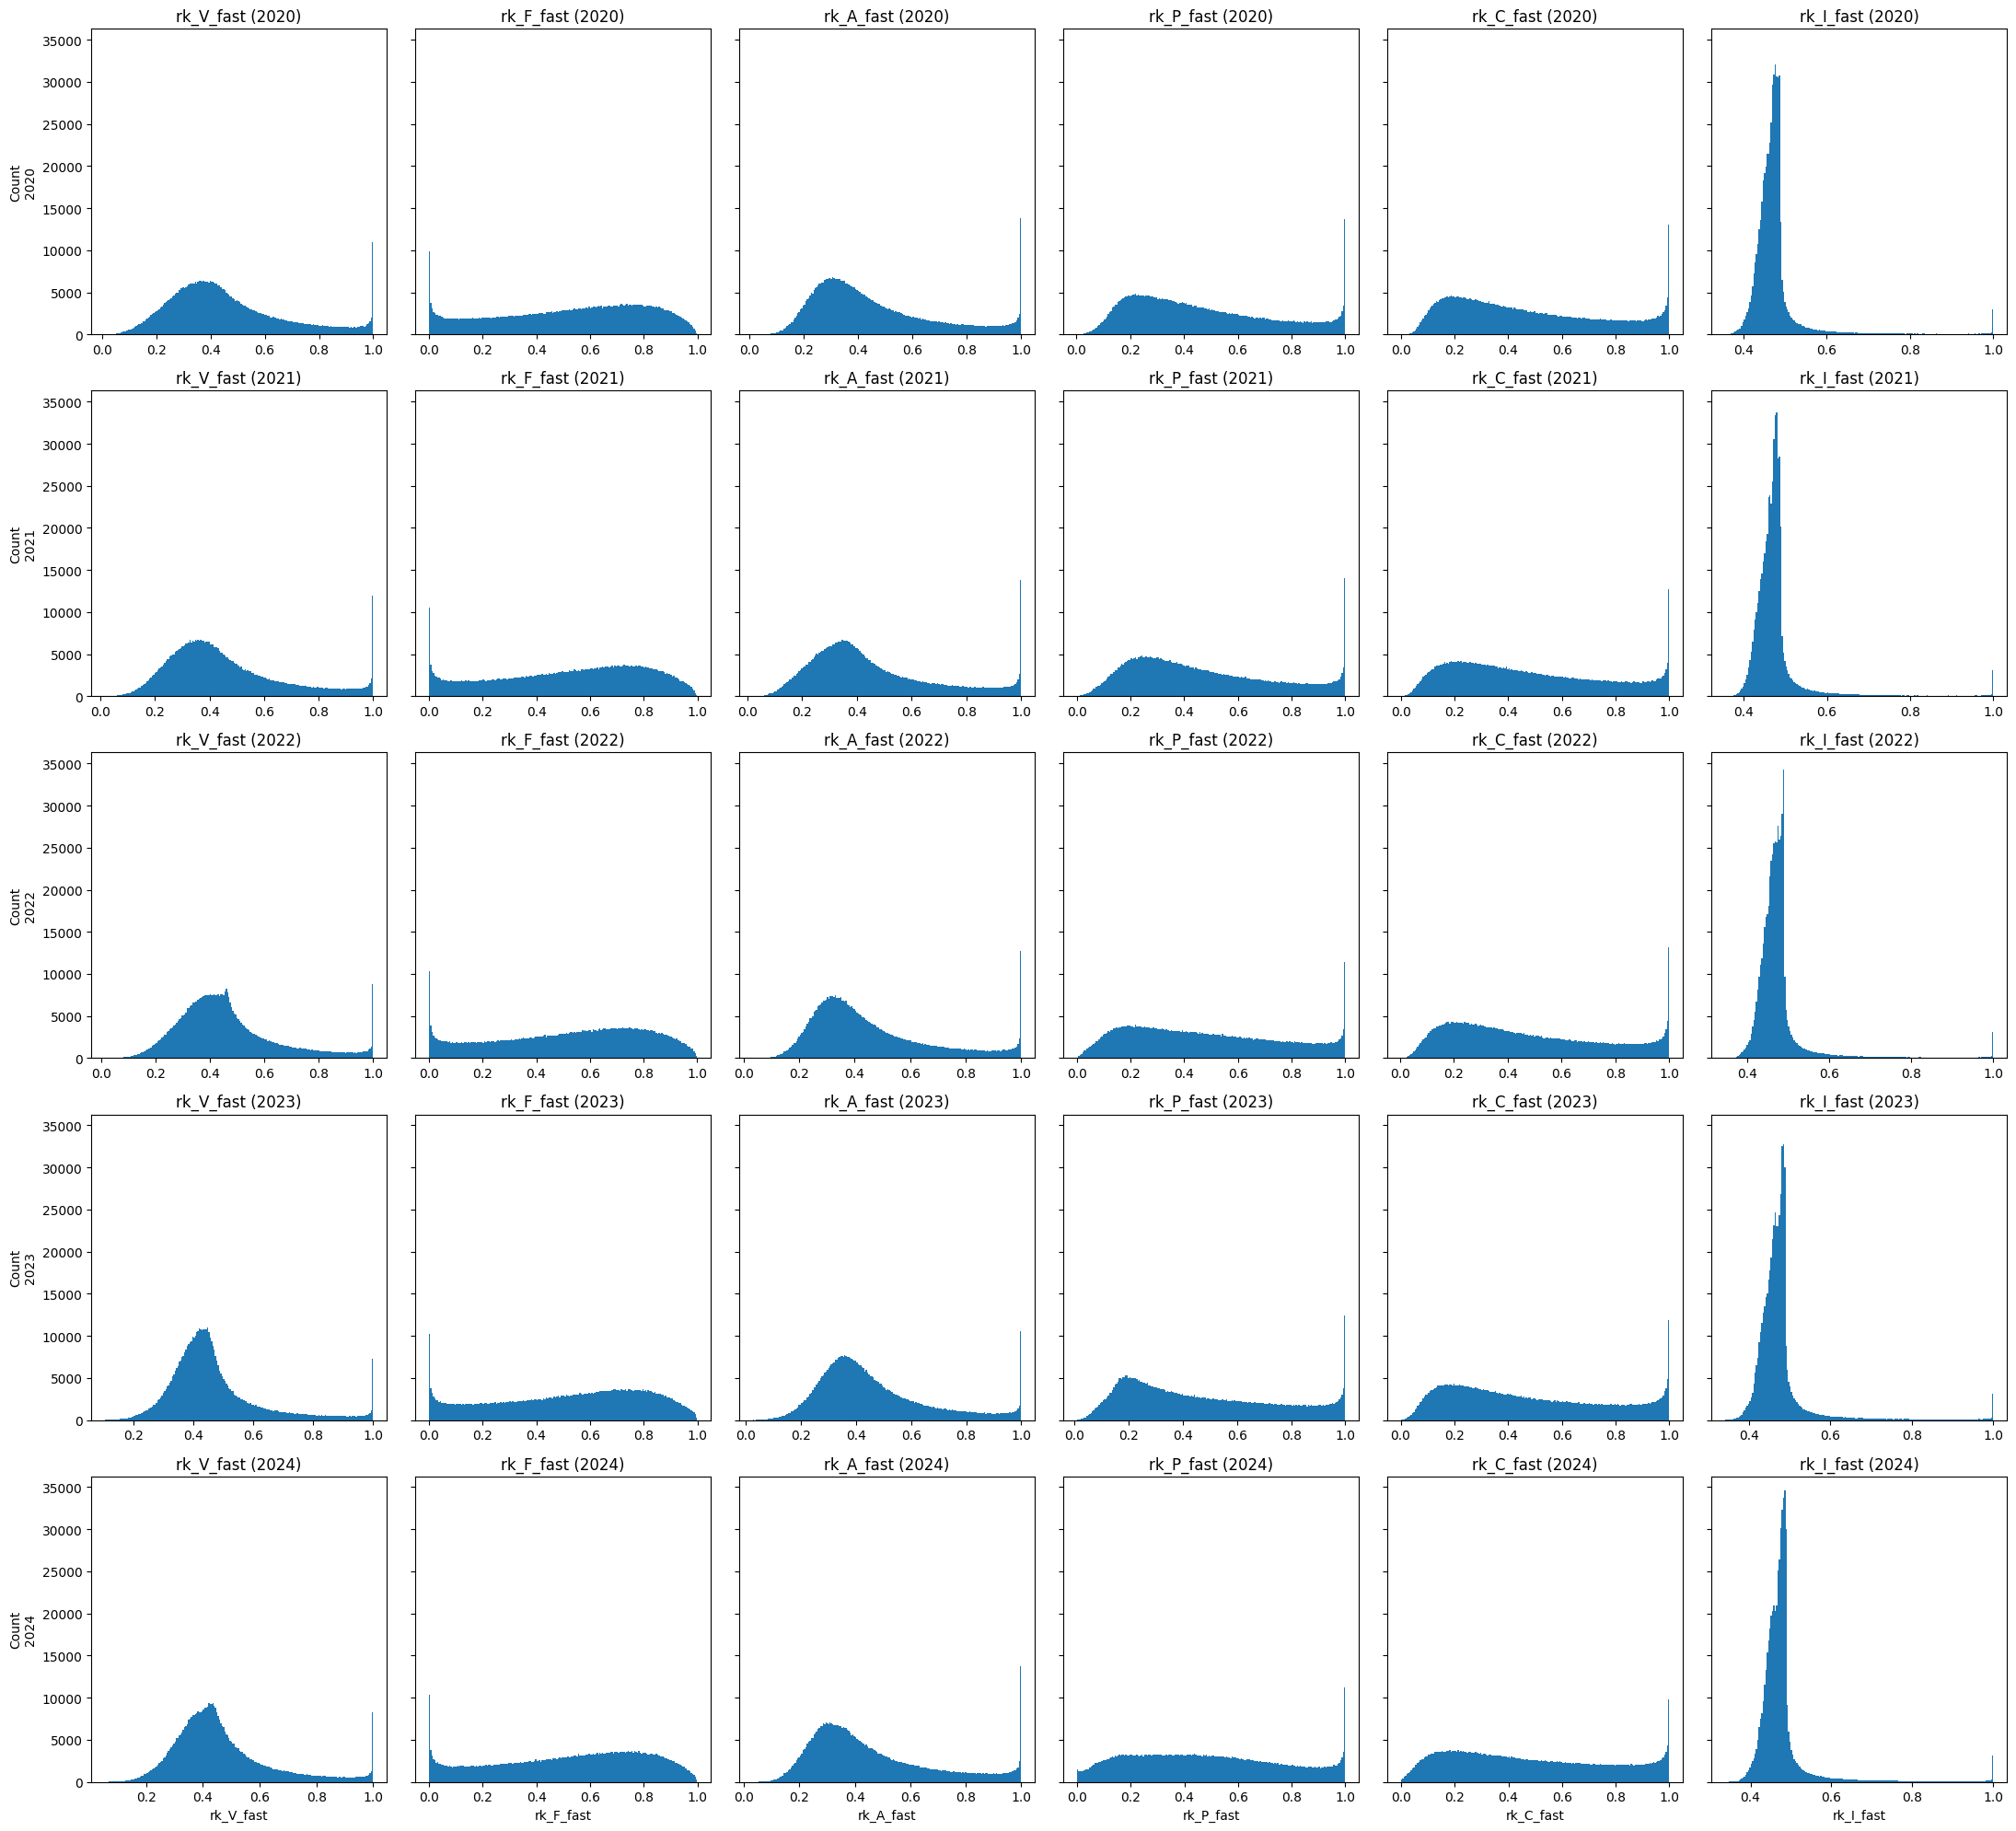

In [ ]:
import matplotlib.pyplot as plt
import polars as pl

years = [2020, 2021, 2022, 2023, 2024]

cols = [
    "rk_V_fast",
    "rk_F_fast",
    "rk_A_fast",
    "rk_P_fast",
    "rk_C_fast",
    "rk_I_fast"
]

fig, axes = plt.subplots(
    len(years), len(cols),
    figsize=(22, 4 * len(years)),
    sharey=True
)

for i, y in enumerate(years):
    df_y = df.filter(pl.col("t").dt.year() == y)

    for j, c in enumerate(cols):
        data = (
            df_y
            .select(c)
            .drop_nulls()
            .to_series()
            .to_numpy()
        )

        axes[i, j].hist(data, bins=200)
        axes[i, j].set_title(f"{c} ({y})")

        if i == len(years) - 1:
            axes[i, j].set_xlabel(c)

    axes[i, 0].set_ylabel(f"Count\n{y}")

plt.tight_layout()
plt.show()

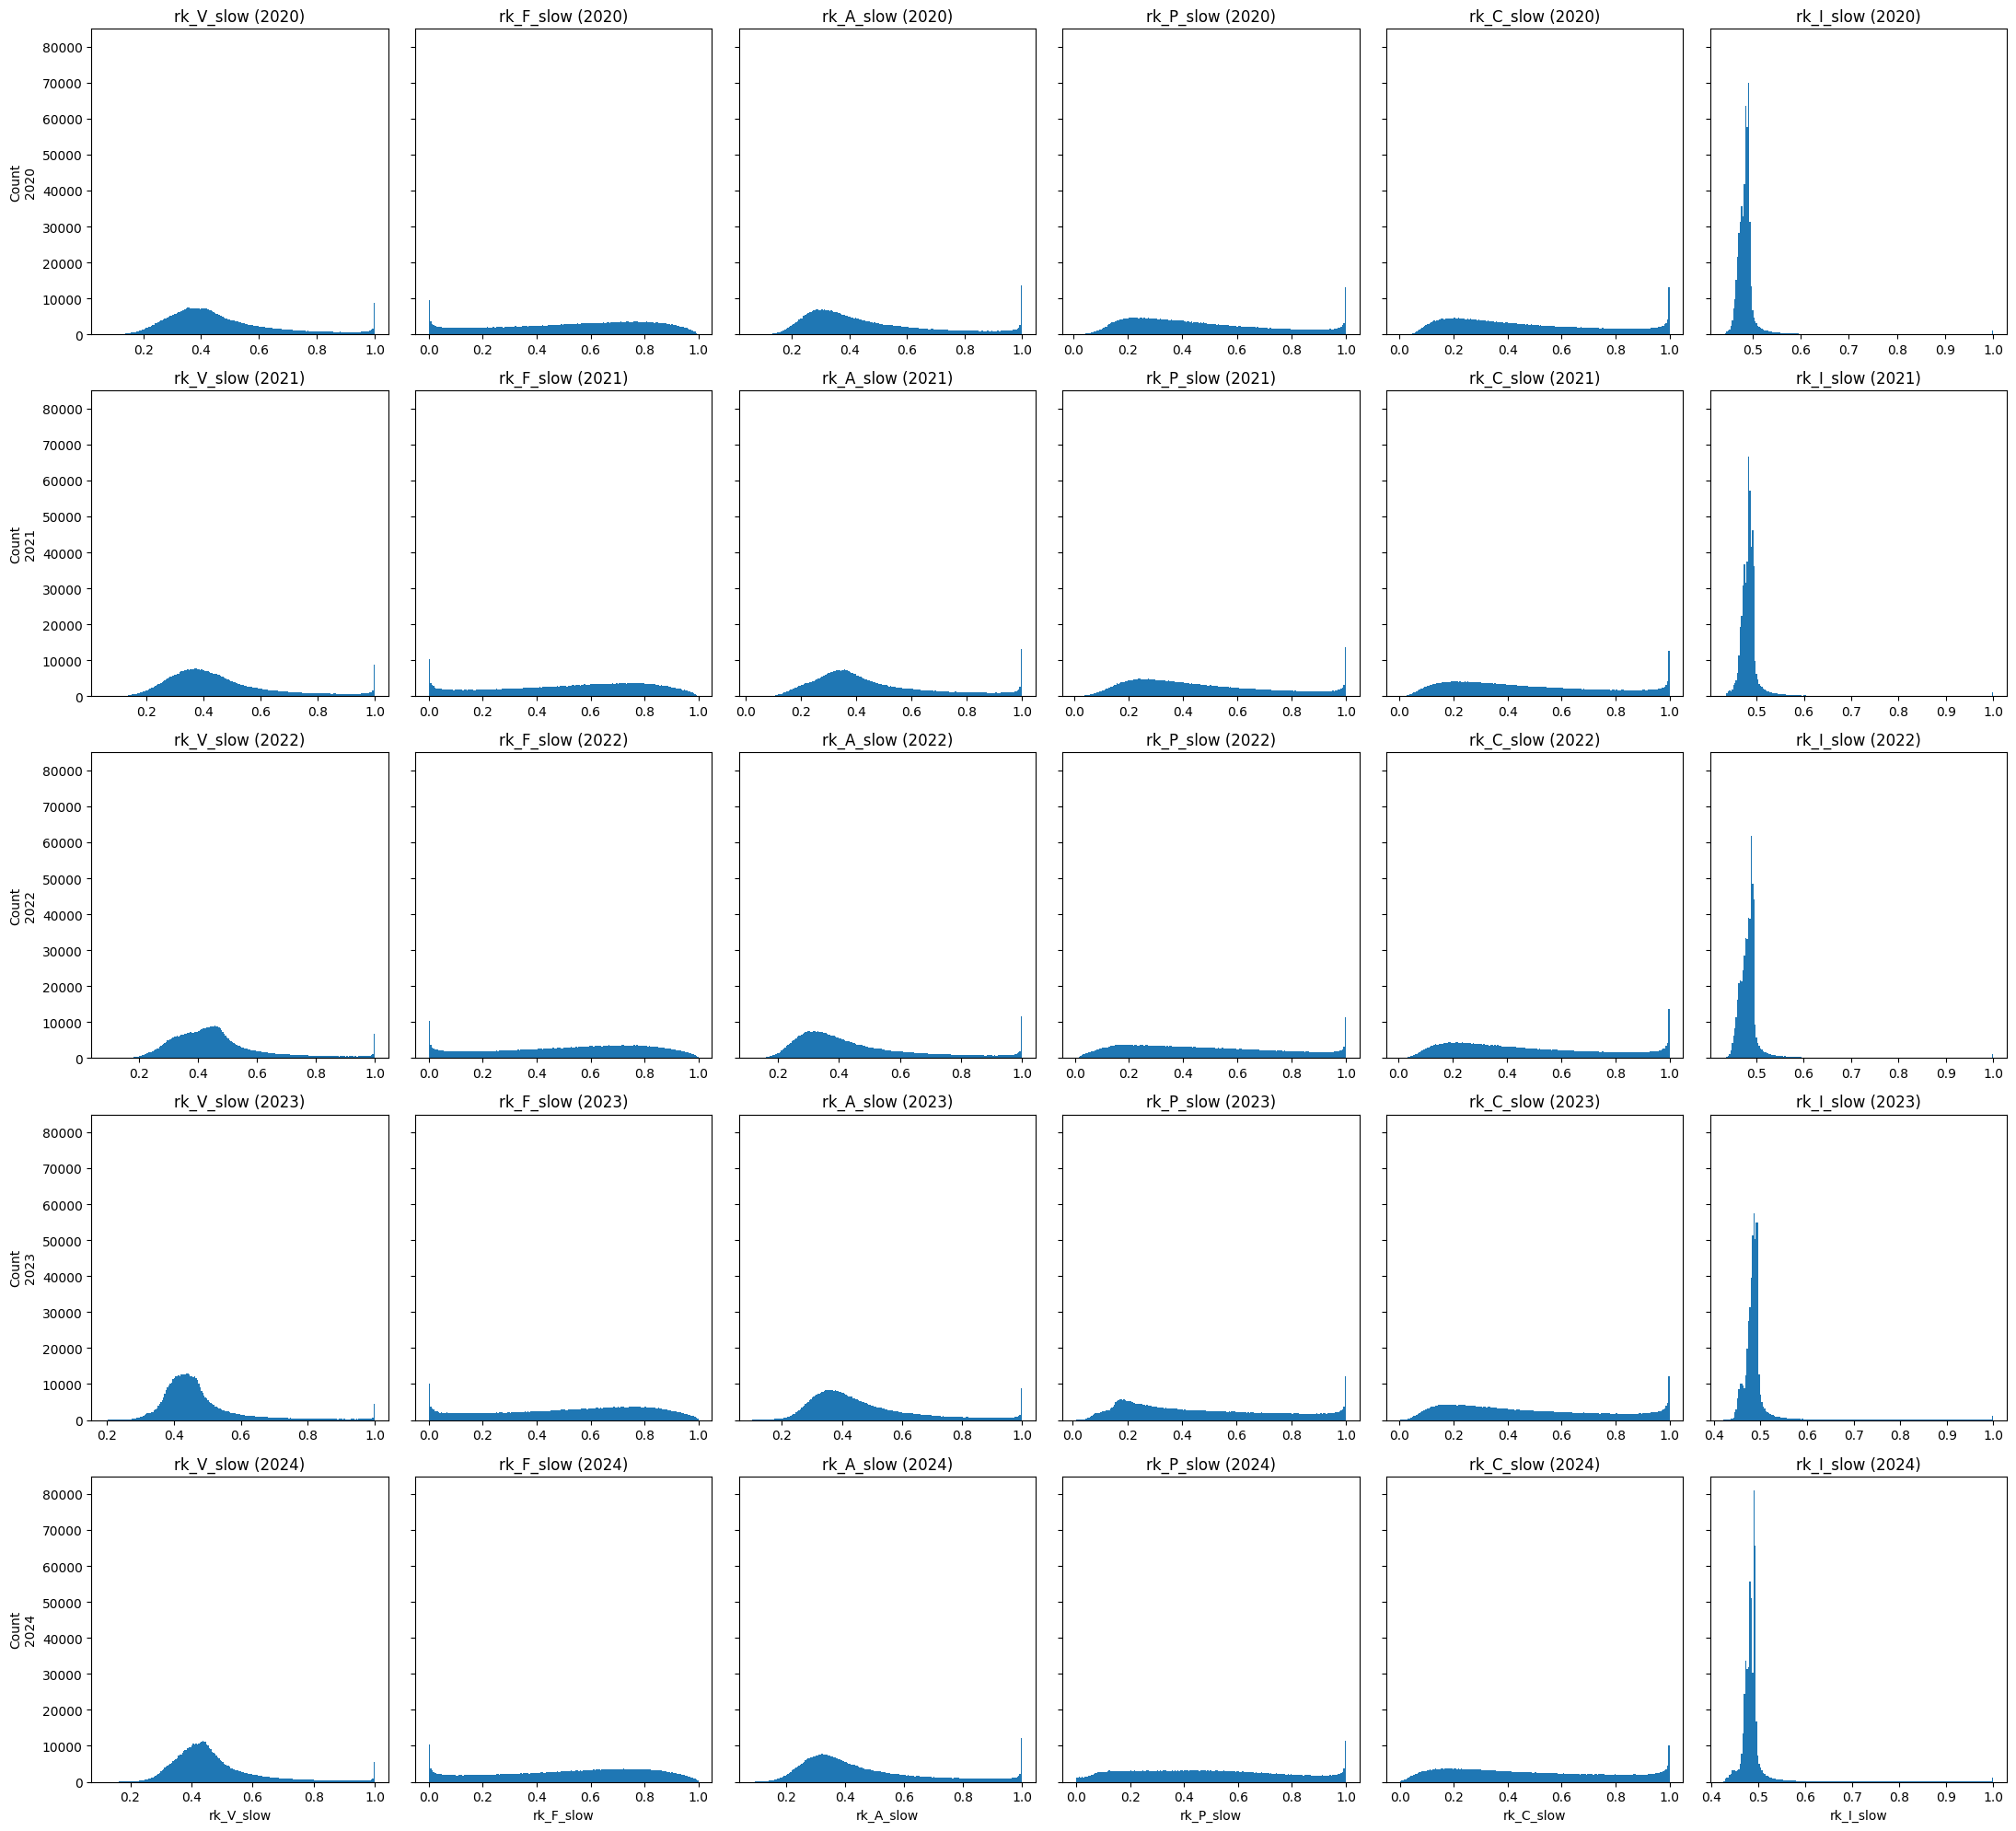

In [ ]:
cols = [
    "rk_V_slow",
    "rk_F_slow",
    "rk_A_slow",
    "rk_P_slow",
    "rk_C_slow",
    "rk_I_slow"
]

fig, axes = plt.subplots(
    len(years), len(cols),
    figsize=(22, 4 * len(years)),
    sharey=True
)

for i, y in enumerate(years):
    df_y = df.filter(pl.col("t").dt.year() == y)

    for j, c in enumerate(cols):
        data = (
            df_y
            .select(c)
            .drop_nulls()
            .to_series()
            .to_numpy()
        )

        axes[i, j].hist(data, bins=200)
        axes[i, j].set_title(f"{c} ({y})")

        if i == len(years) - 1:
            axes[i, j].set_xlabel(c)

    axes[i, 0].set_ylabel(f"Count\n{y}")

plt.tight_layout()
plt.show()

# Raw Behavior Feature Layer

In [ ]:
def add_dist_stats_observed(
    df: pl.DataFrame | pl.LazyFrame,
    *,
    name: str,
    col: str,
    L_minutes: int,
    bar_seconds: int = 60,
    percentiles: tuple[float, ...] = (0.90,),
    min_obs: int | None = None,          # NEW
    prefix: str = "",
    interpolation: str = "nearest",
) -> pl.DataFrame | pl.LazyFrame:

    lf = df.lazy() if isinstance(df, pl.DataFrame) else df

    window = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))
    mo = window if min_obs is None else min_obs

    obs = (
        pl.col(col).is_not_null().cast(pl.UInt32)
        .rolling_sum(window_size=window, min_periods=1)
    )

    exprs: list[pl.Expr] = []

    mean_expr = (
        pl.when(obs >= pl.lit(mo))
        .then(pl.col(col).rolling_mean(window_size=window, min_periods=1))
        .otherwise(None)
        .alias(f"{prefix}{name}_mean_{L_minutes}m")
    )
    exprs.append(mean_expr)

    for q in percentiles:
        p_label = int(round(q * 100))
        q_expr = (
            pl.when(obs >= pl.lit(mo))
            .then(
                pl.col(col).rolling_quantile(
                    quantile=q,
                    window_size=window,
                    min_periods=1,
                    interpolation=interpolation,
                )
            )
            .otherwise(None)
            .alias(f"{prefix}{name}_p{p_label}_{L_minutes}m")
        )
        exprs.append(q_expr)

    out = lf.with_columns(exprs)
    return out.collect() if isinstance(df, pl.DataFrame) else out

In [ ]:
# ---------------------------------------
# Config-driven observed stats
# ---------------------------------------

OBS_CONFIG = {
    "V_log": {
        "col": "V_log",
        "windows": [(60, 30), (240, 120)],
    },
    "A_raw": {
        "col": "A_raw",
        "windows": [(60, 30), (240, 120)],
    },
    "Fabs_log": {
        "col": "Fabs_log",
        "windows": [(60, 30), (240, 120)],
    },
    "P_raw": {"col": "P_raw", "windows": [(60, 30), (240, 120)]},
    "C_raw": {"col": "C_raw", "windows": [(60, 30), (240, 120)]},
    "I_raw": {"col": "I_raw", "windows": [(60, 30), (240, 120)]},
}

for name, cfg in OBS_CONFIG.items():
    for L, min_obs in cfg["windows"]:
        df = add_dist_stats_observed(
            df,
            name=name,
            col=cfg["col"],
            L_minutes=L,
            min_obs=min_obs,
        )


/tmp/ipython-input-869187020.py:21: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-869187020.py:28: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .then(pl.col(col).rolling_mean(window_size=window, min_periods=1))
/tmp/ipython-input-869187020.py:39: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  pl.col(col).rolling_quantile(


In [ ]:
def compute_thresholds_quantile(
    df: pl.DataFrame | pl.LazyFrame,
    specs: dict[str, dict[str, float]],
) -> dict[str, dict[str, float]]:
    """
    specs example:
      {
        "V_log": {"hi": 0.95},
        "A_raw": {"hi": 0.95, "xhi": 0.99},
        "P_raw": {"lo": 0.10, "hi": 0.90},
      }

    Returns:
      {
        "V_log": {"hi": <value>},
        ...
      }
    """
    lf = df.lazy() if isinstance(df, pl.DataFrame) else df

    # build one-pass quantile aggregations
    agg_exprs = []
    for col, flags in specs.items():
        for flag, p in flags.items():
            # alias like "__thr__A_raw__hi"
            agg_exprs.append(pl.col(col).quantile(p).alias(f"__thr__{col}__{flag}"))

    thr_row = lf.select(agg_exprs).collect().row(0)  # tuple
    thr_cols = lf.select(agg_exprs).collect().columns  # names in same order

    flat = dict(zip(thr_cols, thr_row))

    # reshape to nested dict
    out: dict[str, dict[str, float]] = {c: {} for c in specs.keys()}
    for k, v in flat.items():
        # k = "__thr__{col}__{flag}"
        _, col, flag = k.split("__", 2)  # careful: split into 3 parts max
        # Actually k starts with "__thr__", so after split("__", 2) we get ["", "thr", "{col}__{flag}"]
        # Let's parse robustly:
    # Robust parse:
    out = {c: {} for c in specs.keys()}
    for k, v in flat.items():
        # "__thr__A_raw__xhi" -> parts ["", "thr", "A_raw", "xhi"]
        parts = k.split("__")
        col = parts[2]
        flag = parts[3]
        out[col][flag] = float(v) if v is not None else float("nan")

    return out

In [ ]:
def add_flags(
    df: pl.DataFrame | pl.LazyFrame,
    thresholds: dict[str, dict[str, float]],
    *,
    prefix: str = "",
    cast_to_u8: bool = True,
) -> pl.DataFrame | pl.LazyFrame:
    """
    thresholds example:
      {
        "A_raw": {"hi": 0.015, "xhi": 0.045},
      }

    Creates columns:
      f"{prefix}{col}_{flag}" as boolean (or UInt8 if cast_to_u8=True)
    Semantics:
      - 'lo' means x < thr
      - otherwise (hi/xhi/event) means x > thr
    """
    lf = df.lazy() if isinstance(df, pl.DataFrame) else df

    exprs = []
    for col, flags in thresholds.items():
        for flag, thr in flags.items():
            name = f"{prefix}{col}_{flag}"
            if flag == "lo":
                e = (pl.col(col) < pl.lit(thr)).alias(name)
            else:
                e = (pl.col(col) > pl.lit(thr)).alias(name)

            if cast_to_u8:
                e = e.cast(pl.UInt8)

            exprs.append(e)

    out = lf.with_columns(exprs)
    return out.collect() if isinstance(df, pl.DataFrame) else out

In [ ]:
SPECS_PHASE_1P5 = {
    "V_log":   {"hi": 0.95},              # (recommended: drop xhi per CCDF)
    "A_raw":   {"hi": 0.95, "xhi": 0.99},
    "Fabs_log":{"hi": 0.95},
    "P_raw":   {"lo": 0.10, "hi": 0.90},
    "C_raw":   {"hi": 0.95, "xhi": 0.99},
    "I_raw":   {"event": 0.995},          # I_event = I_raw > q99.5
}

In [ ]:
thr = compute_thresholds_quantile(df, SPECS_PHASE_1P5)
df = add_flags(df, thr, prefix="")

In [ ]:
def add_flag_fracs(
    df: pl.DataFrame | pl.LazyFrame,
    *,
    flag_cols: list[str],
    windows_minutes: list[int] = [60, 240],
    bar_seconds: int = 60,
    min_obs: int | None = None,   # ขั้นต่ำของจำนวนจุดที่ "วัดได้" ใน window
    prefix: str = "",
) -> pl.DataFrame | pl.LazyFrame:
    lf = df.lazy() if isinstance(df, pl.DataFrame) else df

    exprs: list[pl.Expr] = []
    for L in windows_minutes:
        if L <= 0:
            raise ValueError("windows_minutes must be positive integers")

        window = max(1, int((L * 60 + bar_seconds - 1) // bar_seconds))
        mo = (window if min_obs is None else min_obs)

        for fcol in flag_cols:
            out_name = f"{prefix}{fcol}_frac_{L}m"

            # numerator: count of 1s (ignore nulls)
            num = (
                pl.col(fcol)
                .cast(pl.UInt8)
                .rolling_sum(window_size=window, min_periods=1)
            )

            # denominator: number of observed (non-null) flags
            den = (
                pl.col(fcol)
                .is_not_null()
                .cast(pl.UInt32)
                .rolling_sum(window_size=window, min_periods=1)
            )

            exprs.append(
                pl.when(den >= pl.lit(mo))
                .then(num / den)
                .otherwise(None)
                .alias(out_name)
            )

    out = lf.with_columns(exprs)
    return out.collect() if isinstance(df, pl.DataFrame) else out

In [ ]:
FLAG_COLS = [
    "V_log_hi",
    "A_raw_hi",
    "A_raw_xhi",
    "Fabs_log_hi",
    "P_raw_lo",
    "P_raw_hi",
    "C_raw_hi",
    "C_raw_xhi",
    "I_raw_event",
]

In [ ]:
df.select(FLAG_COLS).describe()

statistic,V_log_hi,A_raw_hi,A_raw_xhi,Fabs_log_hi,P_raw_lo,P_raw_hi,C_raw_hi,C_raw_xhi,I_raw_event
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3.153974e6,3.153978e6,3.153978e6,2.668868e6,3.151751e6,3.151751e6,3.093724e6,3.093724e6,3.15413e6
"""null_count""",2506.0,2502.0,2502.0,487612.0,4729.0,4729.0,62756.0,62756.0,2350.0
"""mean""",0.05,0.049941,0.009997,0.05,0.099996,0.1,0.05,0.01,0.005
"""std""",0.217945,0.217823,0.099483,0.217945,0.299995,0.3,0.217945,0.099498,0.070534
"""min""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""50%""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""75%""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""max""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [ ]:
df = add_flag_fracs(
    df,
    flag_cols=FLAG_COLS,
    windows_minutes=[60],
    min_obs=30,
)

df = add_flag_fracs(
    df,
    flag_cols=FLAG_COLS,
    windows_minutes=[240],
    min_obs=120,
)

/tmp/ipython-input-283189239.py:27: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-283189239.py:35: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)


In [ ]:
df.select([
    'Fabs_log_hi_frac_60m',
    'Fabs_log_hi_frac_240m'
]).describe()

statistic,Fabs_log_hi_frac_60m,Fabs_log_hi_frac_240m
str,f64,f64
"""count""",2.734841e6,2.747971e6
"""null_count""",421639.0,408509.0
"""mean""",0.050353,0.050536
"""std""",0.062079,0.052546
"""min""",0.0,0.0
"""25%""",0.0,0.016129
"""50%""",0.033333,0.035874
"""75%""",0.066667,0.066667
"""max""",0.95,0.5


In [ ]:
def add_current_runlen(
    df: pl.DataFrame,
    *,
    col: str,
    prefix: str = "",
) -> pl.DataFrame:

    return df.with_columns(
        (
            (pl.col(col) == 1)
            .cast(pl.Int32)
            .cum_sum()
            .over((pl.col(col) == 0).cum_sum())
        )
        .alias(f"{prefix}runlen_{col}")
    )

def add_max_runlen_L(
    df: pl.DataFrame,
    *,
    runlen_col: str,
    L_minutes: int,
    bar_seconds: int = 60,
    min_periods: int | None = None,
    prefix: str = "",
) -> pl.DataFrame:
    """
    Adds max consecutive run length within the last L minutes.

    maxrun_X_hi_L
    """

    if L_minutes <= 0:
        raise ValueError("L_minutes must be > 0")

    window_size = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))
    if min_periods is None:
        min_periods = window_size

    return df.with_columns(
        pl.col(runlen_col)
        .rolling_max(
            window_size=window_size,
            min_periods=min_periods,
        )
        .alias(f"{prefix}maxrun_{runlen_col}_{L_minutes}m")
    )

In [ ]:
core_cols = [
    "P_raw_lo",
    "P_raw_hi",
    "C_raw_hi",
    "C_raw_xhi",
]

# 1) current runlen for each core col
for c in core_cols:
    df = add_current_runlen(df, col=c)

# 2) max runlen within L minutes for each runlen col, for L=60 and 240
for c in core_cols:
    runlen_col = f"runlen_{c}"
    for L in (60, 240):
        df = add_max_runlen_L(df, runlen_col=runlen_col, L_minutes=L, min_periods=int(L/2))

/tmp/ipython-input-3714680951.py:42: DeprecationWarning: the argument `min_periods` for `Expr.rolling_max` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_max(


In [ ]:
def add_flip_rate_L(
    df: pl.DataFrame,
    *,
    col: str,
    L_minutes: int,
    bar_seconds: int = 60,
    min_periods: int | None = None,
    prefix: str = "",
) -> pl.DataFrame:
    """
    Adds flip rate of a binary flag over the last L minutes.

    flip_rate_X_L = (# of state changes) / L
    """

    if L_minutes <= 0:
        raise ValueError("L_minutes must be > 0")

    # minutes -> bars
    window = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))
    if min_periods is None:
        min_periods = window

    flip_col = f"__flip_{col}"

    return (
        df
        # detect state change
        .with_columns(
            (pl.col(col) != pl.col(col).shift(1))
            .cast(pl.UInt8)
            .fill_null(0)
            .alias(flip_col)
        )
        # rolling flip rate
        .with_columns(
            (
                pl.col(flip_col)
                .rolling_sum(window_size=window, min_periods=min_periods)
                / window
            )
            .alias(f"{prefix}{col}_flip_rate_{L_minutes}m")
        )
        .drop(flip_col)
    )

In [ ]:
df = add_flip_rate_L(
    df,
    col="P_raw_lo",
    L_minutes=60,
    min_periods=30
)
df = add_flip_rate_L(
    df,
    col="P_raw_lo",
    L_minutes=240,
    min_periods=120
)

df = add_flip_rate_L(
    df,
    col="P_raw_hi",
    L_minutes=60,
    min_periods=30
)
df = add_flip_rate_L(
    df,
    col="P_raw_hi",
    L_minutes=240,
    min_periods=120
)

df = add_flip_rate_L(
    df,
    col="C_raw_hi",
    L_minutes=60,
    min_periods=30
)
df = add_flip_rate_L(
    df,
    col="C_raw_hi",
    L_minutes=240,
    min_periods=120
)

df = add_flip_rate_L(
    df,
    col="C_raw_xhi",
    L_minutes=60,
    min_periods=30
)
df = add_flip_rate_L(
    df,
    col="C_raw_xhi",
    L_minutes=240,
    min_periods=120
)

/tmp/ipython-input-319867762.py:39: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=min_periods)


In [ ]:
df.columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'signed_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'active_ms',
 'intensity_peak_1s',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_q',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'run_max',
 'run_mean',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'A_t',
 'F_t',
 'P_t',
 'C_t',
 'V_t',
 'I_t',
 'eps_I',
 'I_t_filled',
 'V_log',
 'F_raw',
 'Fabs_log',
 'A_raw',
 'P_raw',
 'C_raw',
 'I_raw',
 'rk_V_fast',
 'rk

# Rolling Behavior Feature Layer

In [ ]:
import polars as pl


def add_rank_flags(
    df: pl.DataFrame,
    *,
    name: str,                     # "V", "F", "A", "P"
    slow_col: str | None = None,   # e.g. "rk_V_slow"
    fast_col: str | None = None,   # e.g. "rk_V_fast"
    hi_th: float | None = 0.80,
    xhi_th: float | None = 0.9,
    lo_th: float | None = 0.20,
    xlo_th: float | None = 0.10,
    spike_th: float | None = 0.99,
    prefix: str = "",
) -> pl.DataFrame:
    """
    Add boolean regime / shock flags from rank features.

    Only adds columns if:
      - the source column is provided
      - the threshold is not None
    """

    exprs: list[pl.Expr] = []

    # ---- High regime (slow) ----
    if slow_col is not None and hi_th is not None:
        exprs.append(
            (pl.col(slow_col) > hi_th)
            .cast(pl.UInt8)
            .alias(f"{prefix}{name}_hi")
        )

    # ---- Extreme high (slow) ----
    if slow_col is not None and xhi_th is not None:
        exprs.append(
            (pl.col(slow_col) > xhi_th)
            .cast(pl.UInt8)
            .alias(f"{prefix}{name}_xhi")
        )

    # ---- Low regime (slow) ----
    if slow_col is not None and lo_th is not None:
        exprs.append(
            (pl.col(slow_col) < lo_th)
            .cast(pl.UInt8)
            .alias(f"{prefix}{name}_lo")
        )

    # ---- Low regime (slow) ----
    if slow_col is not None and xlo_th is not None:
        exprs.append(
            (pl.col(slow_col) < xlo_th)
            .cast(pl.UInt8)
            .alias(f"{prefix}{name}_xlo")
        )

    # ---- Fast spike / shock ----
    if fast_col is not None and spike_th is not None:
        exprs.append(
            (pl.col(fast_col) > spike_th)
            .cast(pl.UInt8)
            .alias(f"rk_fast_{name}_spike")
        )

    # nothing to add → return df as-is
    if not exprs:
        return df

    return df.with_columns(exprs)

In [ ]:
df = add_rank_flags(
    df,
    prefix="rk_slow_",
    name="V",
    slow_col="rk_V_slow",
    fast_col="rk_V_fast",
    hi_th=0.8, # expansion
    xhi_th=0.9, # tail risk / regime break
    lo_th=None,
    xlo_th=None,
    spike_th=0.99,
)

df = add_rank_flags(
    df,
    prefix="rk_slow_",
    name="Fabs",
    slow_col="rk_Fabs_slow",
    fast_col="rk_Fabs_fast",
    hi_th=0.85, # imbalance จริง
    xhi_th=0.93, # aggressive one-sided flow (ใช้เป็น event trigger ได้)
    lo_th=None,
    xlo_th=None,
    spike_th=0.99,
)

df = add_rank_flags(
    df,
    prefix="rk_slow_",
    name="A",
    slow_col="rk_A_slow",
    fast_col="rk_A_fast",
    hi_th=0.85, # มี participation พอให้ regime “อยู่ตัว”
    xhi_th=0.95, # crowd / session open / event
    lo_th=0.2,
    xlo_th=None,
    spike_th=None,
)

In [ ]:
df.select([
    "rk_slow_V_hi",
    "rk_slow_V_xhi",
    "rk_fast_V_spike",
    "rk_slow_Fabs_hi",
    "rk_slow_Fabs_xhi",
    "rk_fast_Fabs_spike",
    "rk_slow_A_hi",
    "rk_slow_A_xhi",
    "rk_slow_A_lo",
])

rk_slow_V_hi,rk_slow_V_xhi,rk_fast_V_spike,rk_slow_Fabs_hi,rk_slow_Fabs_xhi,rk_fast_Fabs_spike,rk_slow_A_hi,rk_slow_A_xhi,rk_slow_A_lo,rk_slow_P_lo,rk_slow_P_xlo,rk_slow_C_hi,rk_slow_C_xhi,rk_slow_I_xhi,rk_fast_I_spike
u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0,0,0,null,null,null,0,0,0,0,0,0,0,0,0
0,0,0,null,null,null,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,1,1,0,0


In [ ]:
def add_rank_dist_stats(
    df: pl.DataFrame,
    *,
    name: str,                 # e.g. "V", "F", "A", "P"
    col: str,                  # e.g. "rk_V_slow"
    L_minutes: int,            # e.g. 60
    bar_seconds: int = 60,     # 1m bars default
    percentiles: tuple[float, ...] = (0.90,),  # e.g. (0.5, 0.9, 0.95)
    min_periods: int | None = None,
    prefix: str = "",
    interpolation: str = "nearest",  # "nearest" | "linear" | "higher" | "lower" | "midpoint"
) -> pl.DataFrame:
    """
    Adds rolling distribution summary stats over the last L_minutes.

    Output columns:
      {prefix}{name}_mean_{L}m
      {prefix}{name}_pXX_{L}m   for each percentile in `percentiles`
    """

    if L_minutes <= 0:
        raise ValueError("L_minutes must be > 0")

    # Convert minutes -> number of bars (ceil to be safe)
    window_size = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))
    if min_periods is None:
        min_periods = window_size  # set to 1 if you want early values

    exprs: list[pl.Expr] = []

    # rolling mean
    exprs.append(
        pl.col(col)
        .rolling_mean(window_size=window_size, min_periods=min_periods)
        .alias(f"{prefix}{name}_mean_{L_minutes}m")
    )

    # rolling percentiles
    for q in percentiles:
        if not (0.0 < q < 1.0):
            raise ValueError(f"percentile {q} must be in (0,1)")
        p_label = int(round(q * 100))
        exprs.append(
            pl.col(col)
            .rolling_quantile(
                quantile=q,
                window_size=window_size,
                min_periods=min_periods,
                interpolation=interpolation,
            )
            .alias(f"{prefix}{name}_p{p_label}_{L_minutes}m")
        )

    return df.with_columns(exprs)

In [ ]:
df = add_rank_dist_stats(
    df,
    prefix="rk_slow_",
    name="V",
    col="rk_V_slow",
    L_minutes=60,
    percentiles=(0.90,),
    min_periods=30,  # หรือ None = ต้องครบ 60 นาทีถึงเริ่มมีค่า
)

df = add_rank_dist_stats(
    df,
    prefix="rk_slow_",
    name="V",
    col="rk_V_slow",
    L_minutes=240,
    percentiles=(0.90,),
    min_periods=120,
)

df = add_rank_dist_stats(
    df,
    prefix="rk_slow_",
    name="Fabs",
    col="rk_Fabs_slow",
    L_minutes=60,
    percentiles=(0.90,),
    min_periods=30,
)

df = add_rank_dist_stats(
    df,
    prefix="rk_slow_",
    name="Fabs",
    col="rk_Fabs_slow",
    L_minutes=240,
    percentiles=(0.90,),
    min_periods=120,
)

df = add_rank_dist_stats(
    df,
    prefix="rk_slow_",
    name="A",
    col="rk_A_slow",
    L_minutes=60,
    percentiles=(0.90,),
    min_periods=30,
)

df = add_rank_dist_stats(
    df,
    prefix="rk_slow_",
    name="A",
    col="rk_A_slow",
    L_minutes=240,
    percentiles=(0.90,),
    min_periods=120,
)

/tmp/ipython-input-373572749.py:34: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=window_size, min_periods=min_periods)
/tmp/ipython-input-373572749.py:45: DeprecationWarning: the argument `min_periods` for `Expr.rolling_quantile` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_quantile(


In [ ]:
df.select([
    "rk_slow_V_mean_60m", "rk_slow_V_p90_60m", "rk_slow_V_mean_240m", "rk_slow_V_p90_240m",
    "rk_slow_Fabs_mean_60m", "rk_slow_Fabs_p90_60m", "rk_slow_Fabs_mean_240m", "rk_slow_Fabs_p90_240m",
    "rk_slow_A_mean_60m", "rk_slow_A_p90_60m", "rk_slow_A_mean_240m", "rk_slow_A_p90_240m",
])

rk_slow_V_mean_60m,rk_slow_V_p90_60m,rk_slow_V_mean_240m,rk_slow_V_p90_240m,rk_slow_Fabs_mean_60m,rk_slow_Fabs_p90_60m,rk_slow_Fabs_mean_240m,rk_slow_Fabs_p90_240m,rk_slow_A_mean_60m,rk_slow_A_p90_60m,rk_slow_A_mean_240m,rk_slow_A_p90_240m,rk_slow_P_mean_60m,rk_slow_P_p90_60m,rk_slow_P_mean_240m,rk_slow_P_p90_240m,rk_slow_C_mean_60m,rk_slow_C_p90_60m,rk_slow_C_mean_240m,rk_slow_C_p90_240m,rk_slow_I_mean_60m,rk_slow_I_p90_60m,rk_slow_I_mean_240m,rk_slow_I_p90_240m
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.397249,0.448789,0.424229,0.493933,null,null,null,null,0.361815,0.490129,0.412844,0.581736,0.618648,0.976678,0.578614,0.969239,0.320858,0.693721,0.400529,0.814297,0.452249,0.801332,0.451106,0.690394
0.397751,0.448789,0.42388,0.493933,null,null,null,null,0.363266,0.490129,0.41258,0.581736,0.627904,0.976678,0.578881,0.969239,0.305965,0.652596,0.399991,0.814297,0.454408,0.801332,0.449231,0.683264
0.398364,0.448789,0.423865,0.493933,null,null,null,null,0.365502,0.490129,0.412953,0.581736,0.618618,0.976678,0.578346,0.969239,0.321113,0.693721,0.401916,0.83321,0.458822,0.801332,0.449581,0.683264


In [ ]:
df.select([
    "F_t","Fabs_log","rk_F_fast"	,"rk_F_slow","rk_Fabs_fast","rk_Fabs_slow","rk_slow_Fabs_mean_60m", "rk_slow_Fabs_p90_60m", "rk_slow_Fabs_mean_240m", "rk_slow_Fabs_p90_240m",
]).describe()

statistic,F_t,Fabs_log,rk_F_fast,rk_F_slow,rk_Fabs_fast,rk_Fabs_slow,rk_slow_Fabs_mean_60m,rk_slow_Fabs_p90_60m,rk_slow_Fabs_mean_240m,rk_slow_Fabs_p90_240m
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",2.668868e6,2.668868e6,2.545736e6,2.539191e6,2.545736e6,2.539191e6,2.628833e6,2.628832e6,2.649839e6,2.649839e6
"""null_count""",487612.0,487612.0,610744.0,617289.0,610744.0,617289.0,527647.0,527648.0,506641.0,506641.0
"""mean""",-8927.028411,12.825293,0.500498,0.500359,0.51983,0.520015,0.520179,0.856057,0.520295,0.858483
"""std""",1.2259e6,1.304159,0.243432,0.241457,0.274027,0.274208,0.065597,0.055772,0.048295,0.039838
"""min""",-3.8130e7,0.375302,0.0,0.0,0.0,0.0,0.082905,0.004618,0.177764,0.483921
"""25%""",-442728.605301,12.134508,0.333,0.33561,0.304116,0.304054,0.479041,0.824903,0.491612,0.837005
"""50%""",-3274.809323,12.982815,0.501549,0.501528,0.55519,0.55523,0.521497,0.861915,0.521994,0.862247
"""75%""",427273.733315,13.694906,0.667981,0.664857,0.747545,0.74801,0.562813,0.89425,0.551293,0.884473
"""max""",5.1337e7,17.753922,1.0,1.0,0.999808,0.99978,0.914882,0.996466,0.75575,0.988893


In [ ]:
def add_flag_fraction(
    df: pl.DataFrame,
    *,
    name: str,              # e.g. "V", "Fabs", "A", "P"
    col: str,               # e.g. "rk_slow_V_hi"
    L_minutes: int,         # e.g. 60,240
    bar_seconds: int = 60,  # default = 1m bars
    min_periods: int | None = None,
    prefix: str = "",
) -> pl.DataFrame:
    """
    Adds rolling fraction of a binary flag over the last L_minutes.

    frac_X_hi_L = mean(X_hi over last L)

    Output column:
      {prefix}{col}_frac_{L}m
    """

    if L_minutes <= 0:
        raise ValueError("L_minutes must be > 0")

    # minutes -> bars
    window_size = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))
    if min_periods is None:
        min_periods = window_size

    return df.with_columns(
        pl.col(col)
        .rolling_mean(
            window_size=window_size,
            min_periods=min_periods,
        )
        .alias(f"{prefix}{col}_frac_{L_minutes}m")
    )

In [ ]:
df = add_flag_fraction(df, name="V", col="rk_slow_V_hi",  L_minutes=60,  min_periods=30)
df = add_flag_fraction(df, name="V", col="rk_slow_V_xhi", L_minutes=60,  min_periods=30)
df = add_flag_fraction(df, name="V", col="rk_slow_V_hi",  L_minutes=240, min_periods=120)
df = add_flag_fraction(df, name="V", col="rk_slow_V_xhi", L_minutes=240, min_periods=120)
df = add_flag_fraction(df, name="V", col="rk_fast_V_spike", L_minutes=60,  min_periods=30)

df = add_flag_fraction(df, name="Fabs", col="rk_slow_Fabs_hi", L_minutes=60,  min_periods=30)
df = add_flag_fraction(df, name="Fabs", col="rk_slow_Fabs_xhi", L_minutes=60,  min_periods=30)
df = add_flag_fraction(df, name="Fabs", col="rk_slow_Fabs_hi",  L_minutes=240, min_periods=120)
df = add_flag_fraction(df, name="Fabs", col="rk_slow_Fabs_xhi", L_minutes=240, min_periods=120)
df = add_flag_fraction(df, name="Fabs", col="rk_fast_Fabs_spike", L_minutes=60,  min_periods=30)

df = add_flag_fraction(df, name="A", col="rk_slow_A_hi",  L_minutes=60,  min_periods=30)
df = add_flag_fraction(df, name="A", col="rk_slow_A_xhi", L_minutes=60,  min_periods=30)
df = add_flag_fraction(df, name="A", col="rk_slow_A_hi",  L_minutes=240, min_periods=120)
df = add_flag_fraction(df, name="A", col="rk_slow_A_xhi", L_minutes=240, min_periods=120)

/tmp/ipython-input-2015804900.py:30: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(


In [ ]:
df.select([
    "rk_slow_V_hi_frac_60m",
    "rk_slow_V_xhi_frac_60m",
    "rk_slow_V_hi_frac_240m",
    "rk_slow_V_xhi_frac_240m",
    "rk_fast_V_spike_frac_60m",
    "rk_slow_Fabs_hi_frac_60m",
    "rk_slow_Fabs_xhi_frac_60m",
    "rk_slow_Fabs_hi_frac_240m",
    "rk_slow_Fabs_xhi_frac_240m",
    "rk_fast_Fabs_spike_frac_60m",
    "rk_slow_A_hi_frac_60m",
    "rk_slow_A_xhi_frac_60m",
    "rk_slow_A_hi_frac_240m",
    "rk_slow_A_xhi_frac_240m",
])

rk_slow_V_hi_frac_60m,rk_slow_V_xhi_frac_60m,rk_slow_V_hi_frac_240m,rk_slow_V_xhi_frac_240m,rk_fast_V_spike_frac_60m,rk_slow_Fabs_hi_frac_60m,rk_slow_Fabs_xhi_frac_60m,rk_slow_Fabs_hi_frac_240m,rk_slow_Fabs_xhi_frac_240m,rk_fast_Fabs_spike_frac_60m,rk_slow_A_hi_frac_60m,rk_slow_A_xhi_frac_60m,rk_slow_A_hi_frac_240m,rk_slow_A_xhi_frac_240m,rk_slow_P_lo_frac_60m,rk_slow_P_xlo_frac_60m,rk_slow_P_lo_frac_240m,rk_slow_P_xlo_frac_240m,rk_slow_C_hi_frac_60m,rk_slow_C_xhi_frac_60m,rk_slow_C_hi_frac_240m,rk_slow_C_xhi_frac_240m,rk_slow_I_xhi_frac_60m,rk_slow_I_xhi_frac_240m,rk_fast_I_spike_frac_60m
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.016667,0.016667,0.033333,0.020833,0.016667,null,null,null,null,null,0.0,0.0,0.008333,0.008333,0.133333,0.066667,0.158333,0.104167,0.035714,0.017857,0.048035,0.017467,0.016667,0.008333,0.016667
0.016667,0.016667,0.033333,0.020833,0.016667,null,null,null,null,null,0.0,0.0,0.008333,0.008333,0.133333,0.066667,0.158333,0.104167,0.017857,0.0,0.048035,0.017467,0.016667,0.008333,0.016667
0.016667,0.016667,0.033333,0.020833,0.016667,null,null,null,null,null,0.0,0.0,0.008333,0.008333,0.133333,0.066667,0.158333,0.104167,0.035714,0.017857,0.052402,0.021834,0.016667,0.008333,0.016667


In [ ]:
def add_current_runlen(
    df: pl.DataFrame,
    *,
    col: str,
    prefix: str = "",
) -> pl.DataFrame:

    return df.with_columns(
        (
            (pl.col(col) == 1)
            .cast(pl.Int32)
            .cum_sum()
            .over((pl.col(col) == 0).cum_sum())
        )
        .alias(f"{prefix}runlen_{col}")
    )

def add_max_runlen_L(
    df: pl.DataFrame,
    *,
    runlen_col: str,
    L_minutes: int,
    bar_seconds: int = 60,
    min_periods: int | None = None,
    prefix: str = "",
) -> pl.DataFrame:
    """
    Adds max consecutive run length within the last L minutes.

    maxrun_X_hi_L
    """

    if L_minutes <= 0:
        raise ValueError("L_minutes must be > 0")

    window_size = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))
    if min_periods is None:
        min_periods = window_size

    return df.with_columns(
        pl.col(runlen_col)
        .rolling_max(
            window_size=window_size,
            min_periods=min_periods,
        )
        .alias(f"{prefix}maxrun_{runlen_col}_{L_minutes}m")
    )

In [ ]:
core_cols = [
    "rk_slow_V_hi",
    "rk_slow_V_xhi",
    "rk_slow_Fabs_hi",
    "rk_slow_Fabs_xhi",
    "rk_slow_A_hi",
]

# 1) current runlen for each core col
for c in core_cols:
    df = add_current_runlen(df, col=c)

# 2) max runlen within L minutes for each runlen col, for L=60 and 240
for c in core_cols:
    runlen_col = f"runlen_{c}"
    for L in (60, 240):
        df = add_max_runlen_L(df, runlen_col=runlen_col, L_minutes=L)

/tmp/ipython-input-3714680951.py:42: DeprecationWarning: the argument `min_periods` for `Expr.rolling_max` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_max(


In [ ]:
df.select([
    "runlen_rk_slow_V_hi",
    "runlen_rk_slow_V_xhi",
    "runlen_rk_slow_Fabs_hi",
    "runlen_rk_slow_Fabs_xhi",
    "runlen_rk_slow_A_hi",
    "runlen_rk_slow_P_lo",
    "runlen_rk_slow_I_xhi",
    "runlen_rk_slow_C_hi",

    "maxrun_runlen_rk_slow_V_hi_60m",
    "maxrun_runlen_rk_slow_V_hi_240m",
    "maxrun_runlen_rk_slow_V_xhi_60m",
    "maxrun_runlen_rk_slow_V_xhi_240m",

    "maxrun_runlen_rk_slow_Fabs_hi_60m",
    "maxrun_runlen_rk_slow_Fabs_hi_240m",
    "maxrun_runlen_rk_slow_Fabs_xhi_60m",
    "maxrun_runlen_rk_slow_Fabs_xhi_240m",

    "maxrun_runlen_rk_slow_A_hi_60m",
    "maxrun_runlen_rk_slow_A_hi_240m",
])

runlen_rk_slow_V_hi,runlen_rk_slow_V_xhi,runlen_rk_slow_Fabs_hi,runlen_rk_slow_Fabs_xhi,runlen_rk_slow_A_hi,runlen_rk_slow_P_lo,runlen_rk_slow_I_xhi,runlen_rk_slow_C_hi,maxrun_runlen_rk_slow_V_hi_60m,maxrun_runlen_rk_slow_V_hi_240m,maxrun_runlen_rk_slow_V_xhi_60m,maxrun_runlen_rk_slow_V_xhi_240m,maxrun_runlen_rk_slow_Fabs_hi_60m,maxrun_runlen_rk_slow_Fabs_hi_240m,maxrun_runlen_rk_slow_Fabs_xhi_60m,maxrun_runlen_rk_slow_Fabs_xhi_240m,maxrun_runlen_rk_slow_A_hi_60m,maxrun_runlen_rk_slow_A_hi_240m,maxrun_runlen_rk_slow_P_lo_60m,maxrun_runlen_rk_slow_P_lo_240m,maxrun_runlen_rk_slow_I_xhi_60m,maxrun_runlen_rk_slow_I_xhi_240m,maxrun_runlen_rk_slow_C_hi_60m,maxrun_runlen_rk_slow_C_hi_240m
i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0,0,null,null,0,0,0,0,1,1,1,1,null,null,null,null,0,1,3,3,1,1,null,null
0,0,null,null,0,0,0,0,1,1,1,1,null,null,null,null,0,1,3,3,1,1,null,null
0,0,0,0,0,0,0,1,1,1,1,1,null,null,null,null,0,1,3,3,1,1,null,null


In [ ]:
def add_interarrival_stats_L(
    df: pl.DataFrame,
    *,
    col: str,
    L_minutes: int,
    bar_seconds: int = 60,
    prefix: str = "",
) -> pl.DataFrame:
    """
    Adds:
      - {prefix}{col}_interarrival_mean_{L_minutes}m (minutes)
      - {prefix}{col}_interarrival_cv_{L_minutes}m

    Interarrival is computed between "event starts" (rising edge 0->1),
    so consecutive 1s in a run count as ONE event.
    """
    bar_minutes = bar_seconds / 60.0
    window = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))

    # running index
    df = df.with_row_count("__idx")

    # event start: rising edge 0->1
    prev = pl.col(col).shift(1).fill_null(0)
    df = df.with_columns(
        ((pl.col(col) == 1) & (prev != 1)).alias("__event_start")
    )

    # idx only when event starts
    df = df.with_columns(
        pl.when(pl.col("__event_start"))
        .then(pl.col("__idx"))
        .otherwise(None)
        .alias("__event_idx")
    )

    # last event idx forward-filled (for "previous event" lookup)
    df = df.with_columns(
        pl.col("__event_idx").fill_null(strategy="forward").alias("__last_event_idx")
    )

    # gap in bars only on event-start rows: current_idx - previous_event_idx
    df = df.with_columns(
        pl.when(pl.col("__event_start"))
        .then(pl.col("__idx") - pl.col("__last_event_idx").shift(1))
        .otherwise(None)
        .alias("__event_gap")
    )

    # rolling stats on gaps
    mean_col = f"{prefix}{col}_interarrival_mean_{L_minutes}m"
    cv_col   = f"{prefix}{col}_interarrival_cv_{L_minutes}m"

    df = df.with_columns([
        (pl.col("__event_gap")
         .rolling_mean(window_size=window, min_periods=2)
         * bar_minutes
        ).alias(mean_col),

        (pl.col("__event_gap")
         .rolling_std(window_size=window, min_periods=2)
         * bar_minutes
        ).alias("__ia_std"),
    ])

    # CV = std / mean (null if mean is null)
    df = df.with_columns(
        pl.when(pl.col(mean_col).is_not_null())
          .then(pl.col("__ia_std") / (pl.col(mean_col) + 1e-12))
          .otherwise(None)
          .alias(cv_col)
    )

    return df.drop(
        ["__idx", "__event_start", "__event_idx", "__last_event_idx", "__event_gap", "__ia_std"]
    )

In [ ]:
# interarrival mean + CV

df = add_interarrival_stats_L(
    df,
    col="rk_fast_Fabs_spike",
    L_minutes=240,
)

df = add_interarrival_stats_L(
    df,
    col="rk_fast_V_spike",
    L_minutes=240,
)

/tmp/ipython-input-3214047247.py:21: DeprecationWarning: `DataFrame.with_row_count` is deprecated; use `with_row_index` instead. Note that the default column name has changed from 'row_nr' to 'index'.
  df = df.with_row_count("__idx")
/tmp/ipython-input-3214047247.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=window, min_periods=2)
/tmp/ipython-input-3214047247.py:61: DeprecationWarning: the argument `min_periods` for `Expr.rolling_std` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_std(window_size=window, min_periods=2)


In [ ]:
df.select([
    'rk_fast_Fabs_spike_interarrival_mean_240m',	'rk_fast_Fabs_spike_interarrival_cv_240m',	'rk_fast_V_spike_interarrival_mean_240m',	'rk_fast_V_spike_interarrival_cv_240m'
]).describe()

statistic,rk_fast_I_spike_interarrival_mean_240m,rk_fast_I_spike_interarrival_cv_240m,rk_fast_Fabs_spike_interarrival_mean_240m,rk_fast_Fabs_spike_interarrival_cv_240m,rk_fast_V_spike_interarrival_mean_240m,rk_fast_V_spike_interarrival_cv_240m
str,f64,f64,f64,f64,f64,f64
"""count""",2.953263e6,2.953263e6,181276.0,181276.0,1.820748e6,1.820748e6
"""null_count""",203217.0,203217.0,2.975204e6,2.975204e6,1.335732e6,1.335732e6
"""mean""",47.900928,0.901218,377.334386,1.097407,87.483692,1.152821
"""std""",31.752763,0.325504,470.67167,0.398657,85.009387,0.481672
"""min""",2.0,0.0,2.5,0.0,2.0,0.0
"""25%""",27.111111,0.690668,121.0,0.864251,35.5,0.842926
"""50%""",38.333333,0.874783,223.0,1.199792,62.5,1.144442
"""75%""",58.0,1.09375,465.0,1.364241,110.666667,1.418301
"""max""",427.0,2.741135,9436.5,2.296848,1164.5,4.305792


In [ ]:
def add_flip_rate_L(
    df: pl.DataFrame,
    *,
    col: str,
    L_minutes: int,
    bar_seconds: int = 60,
    prefix: str = "",
) -> pl.DataFrame:
    """
    Adds flip rate of a binary flag over the last L minutes.

    flip_rate_X_L = (# of state changes) / L
    """
    min_periods = int(L_minutes/2)

    if L_minutes <= 0:
        raise ValueError("L_minutes must be > 0")

    # minutes -> bars
    window = max(1, int((L_minutes * 60 + bar_seconds - 1) // bar_seconds))
    if min_periods is None:
        min_periods = window

    flip_col = f"__flip_{col}"

    return (
        df
        # detect state change
        .with_columns(
            (pl.col(col) != pl.col(col).shift(1))
            .cast(pl.UInt8)
            .fill_null(0)
            .alias(flip_col)
        )
        # rolling flip rate
        .with_columns(
            (
                pl.col(flip_col)
                .rolling_sum(window_size=window, min_periods=min_periods)
                / window
            )
            .alias(f"{prefix}{col}_flip_rate_{L_minutes}m")
        )
        .drop(flip_col)
    )

In [ ]:
df = add_flip_rate_L(
    df,
    col="rk_slow_V_hi",
    L_minutes=60,
)
df = add_flip_rate_L(
    df,
    col="rk_slow_V_hi",
    L_minutes=240,
)

df = add_flip_rate_L(
    df,
    col="rk_slow_Fabs_hi",
    L_minutes=60,
)
df = add_flip_rate_L(
    df,
    col="rk_slow_Fabs_hi",
    L_minutes=240,
)

df = add_flip_rate_L(
    df,
    col="rk_slow_A_hi",
    L_minutes=60,
)
df = add_flip_rate_L(
    df,
    col="rk_slow_A_hi",
    L_minutes=240,
)

/tmp/ipython-input-2660670462.py:39: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=min_periods)


In [ ]:
df.select([
    "rk_slow_V_hi_flip_rate_60m",
    "rk_slow_V_hi_flip_rate_240m",

    "rk_slow_Fabs_hi_flip_rate_60m",
    "rk_slow_Fabs_hi_flip_rate_240m",

    "rk_slow_A_hi_flip_rate_60m",
    "rk_slow_A_hi_flip_rate_240m",
])

rk_slow_V_hi_flip_rate_60m,rk_slow_V_hi_flip_rate_240m,rk_slow_Fabs_hi_flip_rate_60m,rk_slow_Fabs_hi_flip_rate_240m,rk_slow_A_hi_flip_rate_60m,rk_slow_A_hi_flip_rate_240m,rk_slow_P_lo_flip_rate_60m,rk_slow_P_lo_flip_rate_240m,rk_slow_C_hi_flip_rate_60m,rk_slow_C_hi_flip_rate_240m
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null
null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…
0.033333,0.066667,0.033333,0.066667,0.0,0.016667,0.166667,0.216667,0.066667,0.075
0.033333,0.066667,0.033333,0.066667,0.0,0.016667,0.166667,0.216667,0.05,0.075
0.033333,0.066667,0.033333,0.066667,0.0,0.016667,0.166667,0.216667,0.05,0.079167


In [ ]:
len(df.columns)

220

In [ ]:
# import matplotlib.pyplot as plt

# cols = ["V_mean_240m","V_mean_60m","V_p90_60m","A_mean_60m","F_mean_60m","rk_fast_P_mean_60m"]

# fig, axes = plt.subplots(1, len(cols), figsize=(22, 4), sharey=False)

# for ax, c in zip(axes, cols):
#     data = (
#         df
#         .select(c)
#         .to_series()
#         .drop_nulls()
#         .to_numpy()
#     )
#     ax.hist(data, bins=200)
#     ax.set_title(c)
#     ax.set_xlabel(c)

# axes[0].set_ylabel("Count")
# plt.tight_layout()
# plt.show()

In [ ]:
len(df.columns)

244

In [ ]:
df.write_parquet(str(data_path("0.Data -> Facts/phase_data/phase_2-1_ETH_1min_Market_Structure_Behavior_Feature.parquet")))